In [96]:
required_packages <- c("tidyverse", "caret", "randomForest", "corrplot", "ggcorrplot")
missing_packages <- required_packages[!vapply(required_packages, requireNamespace, logical(1), quietly = TRUE)]

if (length(missing_packages) > 0) {
  install.packages(missing_packages, repos = "https://cloud.r-project.org")
}

invisible(lapply(required_packages, library, character.only = TRUE))

In [97]:
dataset_path <- Sys.getenv("ZOMATO_CSV", unset = "")
if (!nzchar(dataset_path)) {
  candidates <- c("zomato.csv", file.path("data", "zomato.csv"), "/content/zomato.csv")
  existing_files <- candidates[file.exists(candidates)]
  if (length(existing_files) > 0) dataset_path <- existing_files[[1]]
}

if (!nzchar(dataset_path) || !file.exists(dataset_path)) {
  if (interactive()) {
    message("Select the Zomato restaurant CSV file (not the Online Retail data.csv file).")
    dataset_path <- file.choose()
  } else {
    stop("Zomato CSV not found. Set ZOMATO_CSV or place zomato.csv in the working directory.")
  }
}
if (!file.exists(dataset_path)) stop("Selected CSV file does not exist: ", dataset_path)

zomato <- as.data.frame(readr::read_csv(
  dataset_path,
  show_col_types = FALSE,
  name_repair = "minimal"
))
names(zomato) <- make.names(names(zomato), unique = TRUE)

required_columns <- c("rate", "online_order", "book_table", "votes", "location", "rest_type")
missing_columns <- setdiff(required_columns, names(zomato))
if (length(missing_columns) > 0) {
  stop(
    "This is not the expected Zomato restaurant dataset. Missing columns: ",
    paste(missing_columns, collapse = ", ")
  )
}

dim(zomato)
names(zomato)

[1] 51717    17

[1] "url"                         "address"                    
 [3] "name"                        "online_order"               
 [5] "book_table"                  "rate"                       
 [7] "votes"                       "phone"                      
 [9] "location"                    "rest_type"                  
[11] "dish_liked"                  "cuisines"                   
[13] "approx_cost.for.two.people." "reviews_list"               
[15] "menu_item"                   "listed_in.type."            
[17] "listed_in.city."

In [98]:
str(zomato)
summary(zomato)
colSums(is.na(zomato))   # count missing values


'data.frame':	51717 obs. of  17 variables:
 $ url                        : chr  "https://www.zomato.com/bangalore/jalsa-banashankari?context=eyJzZSI6eyJlIjpbNTg2OTQsIjE4Mzc1NDc0IiwiNTkwOTAiLCI"| __truncated__ "https://www.zomato.com/bangalore/spice-elephant-banashankari?context=eyJzZSI6eyJlIjpbIjU4Njk0IiwxODM3NTQ3NCwiNT"| __truncated__ "https://www.zomato.com/SanchurroBangalore?context=eyJzZSI6eyJlIjpbIjU4Njk0IiwiMTgzNzU0NzQiLDU5MDkwLCIxODM4Mjk0N"| __truncated__ "https://www.zomato.com/bangalore/addhuri-udupi-bhojana-banashankari?context=eyJzZSI6eyJlIjpbIjU4Njk0IiwiMTgzNzU"| __truncated__ ...
 $ address                    : chr  "942, 21st Main Road, 2nd Stage, Banashankari, Bangalore" "2nd Floor, 80 Feet Road, Near Big Bazaar, 6th Block, Kathriguppe, 3rd Stage, Banashankari, Bangalore" "1112, Next to KIMS Medical College, 17th Cross, 2nd Stage, Banashankari, Bangalore" "1st Floor, Annakuteera, 3rd Stage, Banashankari, Bangalore" ...
 $ name                       : chr  "Jalsa" "Spice 

        url             address             name          online_order  
 Length   :51717   Length   :51717   Length   :51717   Length   :51717  
 N.unique :51717   N.unique :11495   N.unique : 8792   N.unique :    2  
 N.blank  :    0   N.blank  :    0   N.blank  :    0   N.blank  :    0  
 Min.nchar:  180   Min.nchar:    6   Min.nchar:    2   Min.nchar:    2  
 Max.nchar:  538   Max.nchar:  346   Max.nchar:  159   Max.nchar:    3  
                                                                        
                                                                        
     book_table           rate           votes               phone      
 Length   :51717   Length   :51717   Min.   :    0.0   Length   :51717  
 N.unique :    2   N.unique :   64   1st Qu.:    7.0   N.unique :14926  
 N.blank  :    0   N.blank  :    0   Median :   41.0   N.blank  :    0  
 Min.nchar:    2   Min.nchar:    1   Mean   :  283.7   Min.nchar:   11  
 Max.nchar:    3   Max.nchar:    6   3rd Qu.:  198.

url                     address 
                          0                           0 
                       name                online_order 
                          0                           0 
                 book_table                        rate 
                          0                        7775 
                      votes                       phone 
                          0                        1208 
                   location                   rest_type 
                         21                         227 
                 dish_liked                    cuisines 
                      28078                          45 
approx_cost.for.two.people.                reviews_list 
                        346                           0 
                  menu_item             listed_in.type. 
                          0                           0 
            listed_in.city. 
                          0

In [99]:
rate_text <- trimws(as.character(zomato$rate))
rate_text[toupper(rate_text) %in% c("", "NEW", "-", "NA", "N/A")] <- NA_character_
zomato$rate <- rate_text

In [100]:
# Convert ratings such as "4.1/5" to numeric and reject unexpected formats.
rate_text <- sub("\\s*/\\s*5\\s*$", "", trimws(as.character(zomato$rate)))
parsed_rate <- suppressWarnings(as.numeric(rate_text))
invalid_rate <- !is.na(rate_text) & is.na(parsed_rate)
if (any(invalid_rate)) {
  stop("Unrecognized rating values: ", paste(head(unique(rate_text[invalid_rate]), 10), collapse = ", "))
}
if (any(parsed_rate < 0 | parsed_rate > 5, na.rm = TRUE)) {
  stop("Ratings must be between 0 and 5.")
}
zomato$rate <- parsed_rate
zomato <- dplyr::filter(zomato, !is.na(rate))

head(zomato$rate)
str(zomato$rate)

[1] 4.1 4.1 3.8 3.7 3.8 3.8

 num [1:41665] 4.1 4.1 3.8 3.7 3.8 3.8 3.6 4.6 4 4.2 ...


In [101]:
zomato <- dplyr::filter(zomato, !is.na(rate))

In [102]:
head(zomato$rate)

[1] 4.1 4.1 3.8 3.7 3.8 3.8

In [103]:
# Remove rows with NA in rate
zomato <- zomato %>% filter(!is.na(rate))

In [104]:
# Convert votes to numeric, reporting unexpected values instead of silently dropping them.
votes_text <- trimws(as.character(zomato$votes))
votes_text <- gsub(",", "", votes_text, fixed = TRUE)
votes_text[votes_text == ""] <- NA_character_
votes_value <- suppressWarnings(as.numeric(votes_text))
invalid_votes <- !is.na(votes_text) & is.na(votes_value)
if (any(invalid_votes)) {
  stop("Unrecognized vote counts: ", paste(head(unique(votes_text[invalid_votes]), 10), collapse = ", "))
}
zomato$votes <- votes_value

head(zomato$votes)

[1] 775 787 918  88 166 286

In [105]:
# Convert categorical columns to factors
zomato$online_order <- as.factor(zomato$online_order)
zomato$book_table <- as.factor(zomato$book_table)
zomato$location <- as.factor(zomato$location)
zomato$rest_type <- as.factor(zomato$rest_type)

## Exploratory Data Analysis (Visualization)

### Rating distribution

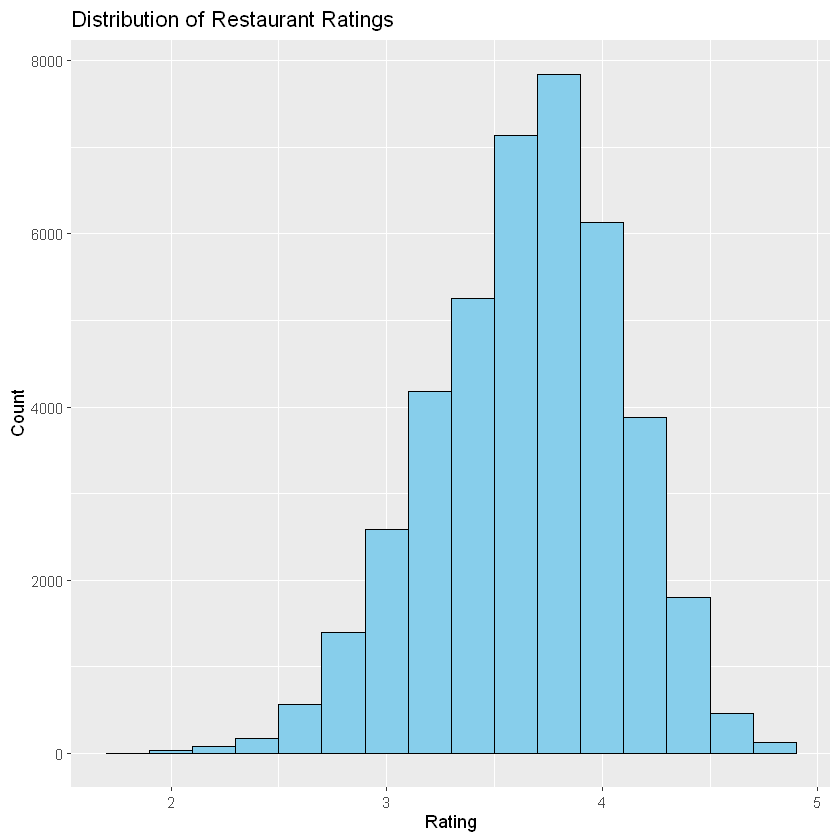

In [106]:
ggplot(zomato, aes(x = rate)) +
  geom_histogram(binwidth = 0.2, fill = "skyblue", color = "black") +
  labs(title = "Distribution of Restaurant Ratings", x = "Rating", y = "Count")


### Online order vs. Rating

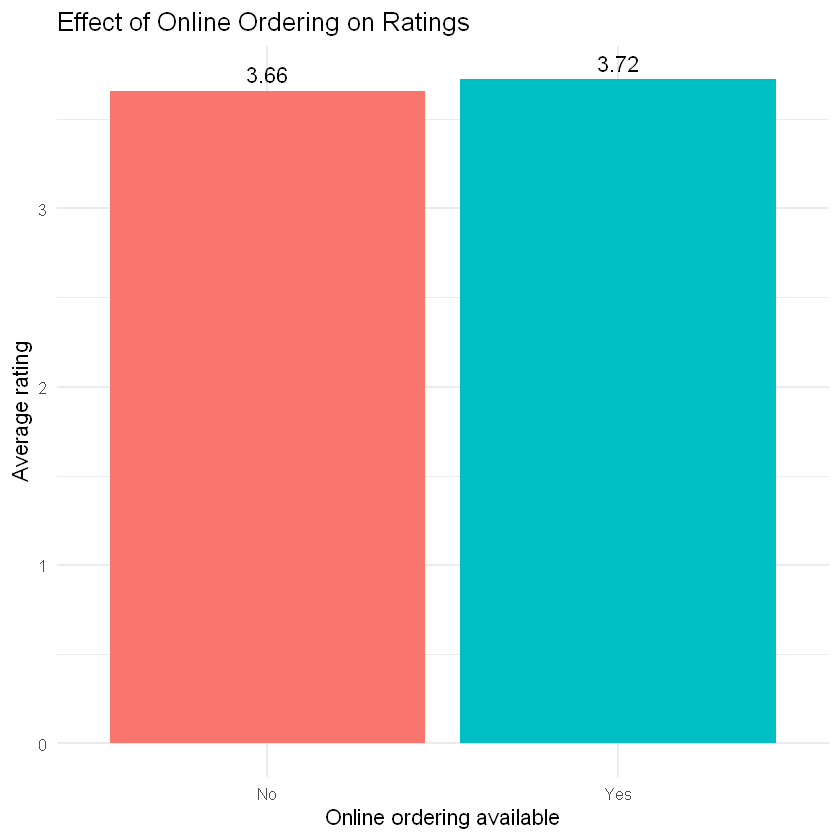

In [107]:
online_avg <- zomato %>%
  group_by(online_order) %>%
  summarise(mean_rate = mean(rate, na.rm = TRUE), .groups = "drop")

ggplot(online_avg, aes(x = online_order, y = mean_rate, fill = online_order)) +
  geom_col() +
  geom_text(aes(label = round(mean_rate, 2)), vjust = -0.5) +
  labs(title = "Effect of Online Ordering on Ratings",
       x = "Online ordering available", y = "Average rating") +
  theme_minimal(base_size = 13) +
  theme(legend.position = "none")

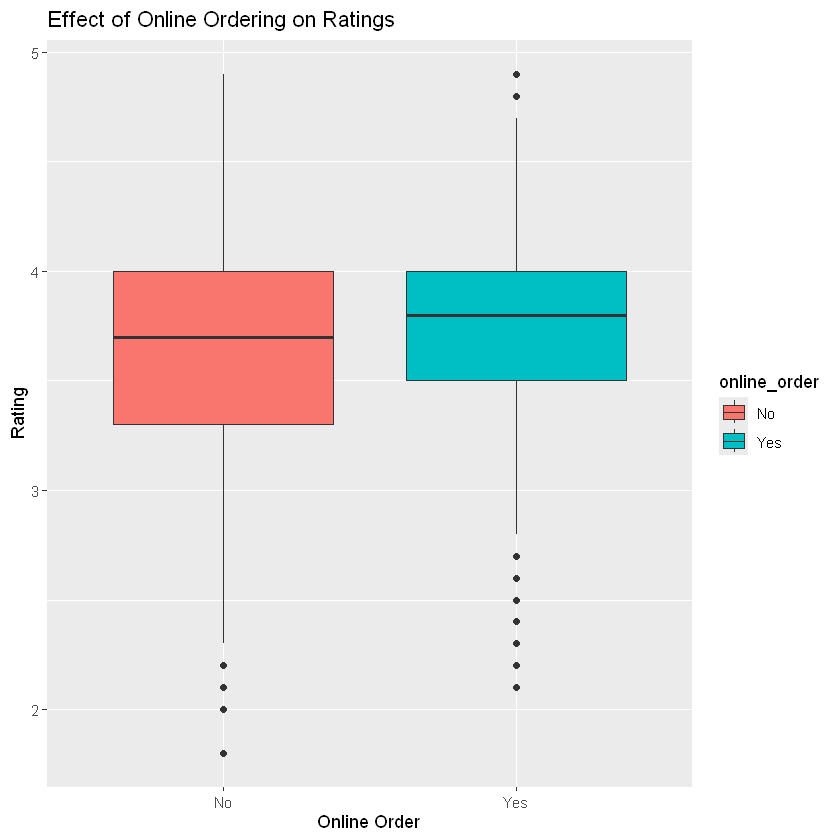

In [108]:
ggplot(zomato, aes(x = online_order, y = rate, fill = online_order)) +
  geom_boxplot() +
  labs(title = "Effect of Online Ordering on Ratings", x = "Online Order", y = "Rating")


### Table booking vs. Rating

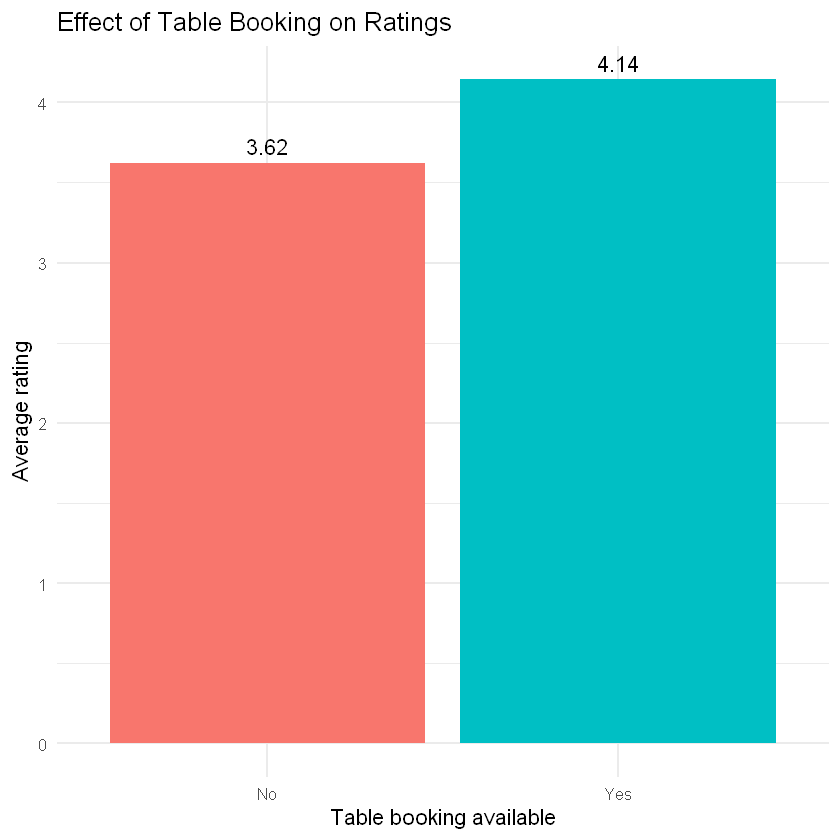

In [109]:
table_avg <- zomato %>%
  group_by(book_table) %>%
  summarise(mean_rate = mean(rate, na.rm = TRUE), .groups = "drop")

ggplot(table_avg, aes(x = book_table, y = mean_rate, fill = book_table)) +
  geom_col() +
  geom_text(aes(label = round(mean_rate, 2)), vjust = -0.5) +
  labs(title = "Effect of Table Booking on Ratings",
       x = "Table booking available", y = "Average rating") +
  theme_minimal(base_size = 13) +
  theme(legend.position = "none")

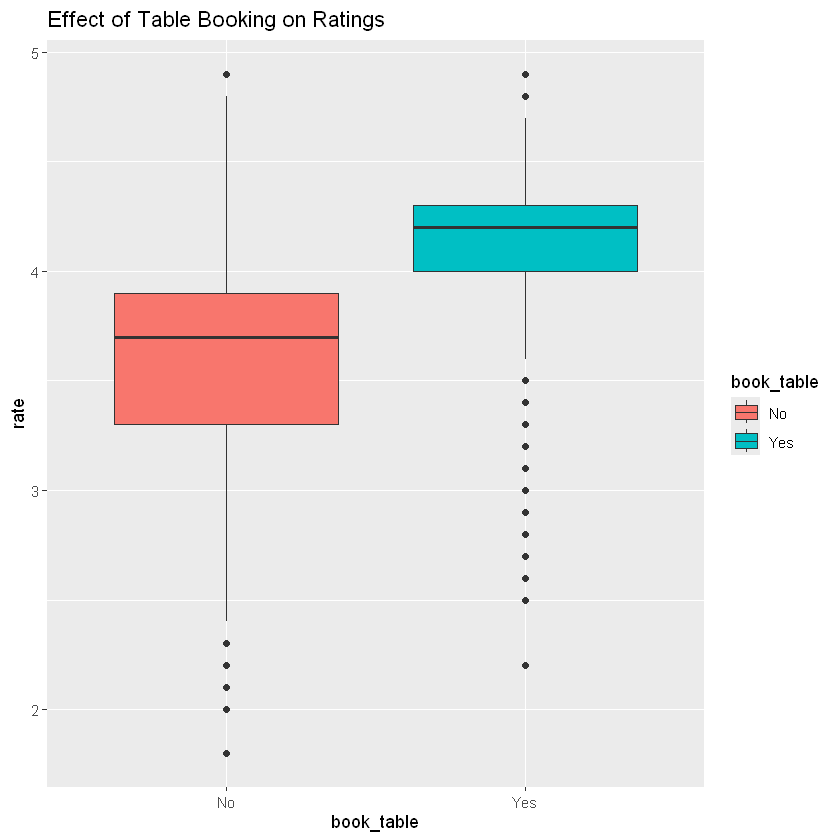

In [110]:
ggplot(zomato, aes(x = book_table, y = rate, fill = book_table)) +
  geom_boxplot() +
  labs(title = "Effect of Table Booking on Ratings")


### Top 10 Locations by Average Rating

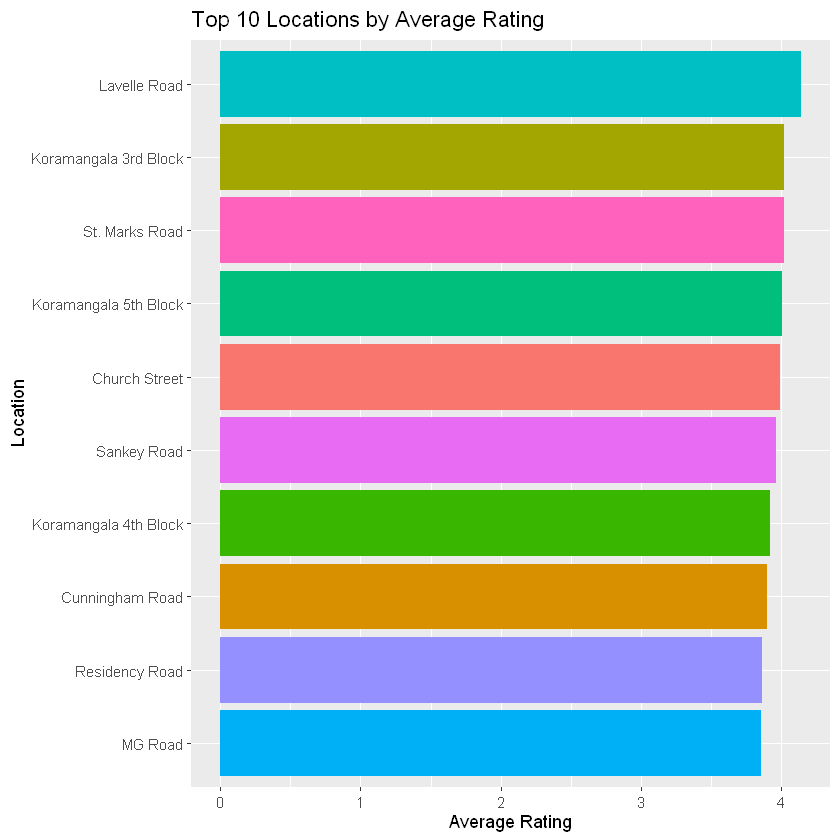

In [111]:
top_locations <- zomato %>%
  group_by(location) %>%
  summarise(avg_rating = mean(rate, na.rm = TRUE)) %>%
  arrange(desc(avg_rating)) %>%
  head(10)

ggplot(top_locations, aes(x = reorder(location, avg_rating), y = avg_rating, fill = location)) +
  geom_col(show.legend = FALSE) +
  coord_flip() +
  labs(title = "Top 10 Locations by Average Rating", x = "Location", y = "Average Rating")


### Restaurant Type Distribution

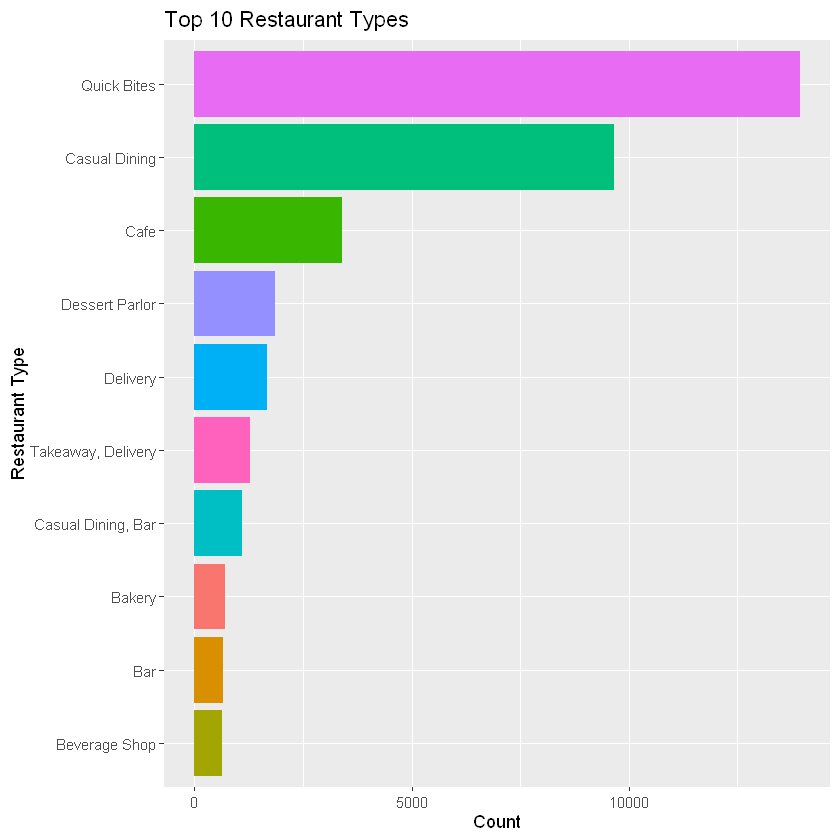

In [112]:
zomato %>%
  count(rest_type) %>%
  arrange(desc(n)) %>%
  head(10) %>%
  ggplot(aes(x = reorder(rest_type, n), y = n, fill = rest_type)) +
  geom_col(show.legend = FALSE) +
  coord_flip() +
  labs(title = "Top 10 Restaurant Types", x = "Restaurant Type", y = "Count")


## Predictive Modeling

### simple Random Forest regression model to predict rate using restaurant features.

In [113]:

# Check which dataset objects currently exist
ls()


[1] "best_location"                      "candidates"                        
  [3] "dataset_path"                       "example"                           
  [5] "example_from_test"                  "existing_files"                    
  [7] "held_out_prediction"                "invalid_rate"                      
  [9] "invalid_votes"                      "location_avg"                      
 [11] "location_count"                     "location_table"                    
 [13] "MAE"                                "mean_actual"                       
 [15] "missing_columns"                    "missing_packages"                  
 [17] "model_columns"                      "novelty1_C"                        
 [19] "novelty1_col"                       "novelty1_m"                        
 [21] "novelty1_missing"                   "novelty1_missing_columns"          
 [23] "novelty1_plot_data"                 "novelty1_rankings"                 
 [25] "novelty1_rate"                      "novelty1_rate_text"                
 [27] "novelty1_raw"                       "novelty1_required_columns"         
 [29] "novelty1_restaurants"               "novelty1_source"                   
 [31] "novelty1_valid_rate"                "novelty1_valid_votes"              
 [33] "novelty1_value"                     "novelty1_vote_text"                
 [35] "novelty1_votes"                     "novelty2_col"                      
 [37] "novelty2_columns"                   "novelty2_complete"                 
 [39] "novelty2_cv_lm"                     "novelty2_cv_lm_pred"               
 [41] "novelty2_cv_prepared"               "novelty2_cv_results"               
 [43] "novelty2_cv_rf"                     "novelty2_cv_rf_pred"               
 [45] "novelty2_cv_rows"                   "novelty2_cv_summary"               
 [47] "novelty2_cv_train"                  "novelty2_cv_valid"                 
 [49] "novelty2_data"                      "novelty2_fold"                     
 [51] "novelty2_folds"                     "novelty2_gbm_available"            
 [53] "novelty2_gbm_model"                 "novelty2_lm_model"                 
 [55] "novelty2_lm_predictions"            "novelty2_metrics"                  
 [57] "novelty2_missing_columns"           "novelty2_missing_packages"         
 [59] "novelty2_plot_data"                 "novelty2_prediction_sets"          
 [61] "novelty2_prepare_features"          "novelty2_prepared"                 
 [63] "novelty2_rate"                      "novelty2_rate_text"                
 [65] "novelty2_raw"                       "novelty2_required_packages"        
 [67] "novelty2_results"                   "novelty2_rf_model"                 
 [69] "novelty2_rf_predictions"            "novelty2_test"                     
 [71] "novelty2_test_metrics"              "novelty2_test_raw"                 
 [73] "novelty2_train"                     "novelty2_train_raw"                
 [75] "novelty2_train_rows"                "novelty2_valid_index"              
 [77] "novelty2_vote_text"                 "novelty2_votes"                    
 [79] "novelty3_background"                "novelty3_background_rows"          
 [81] "novelty3_background_rows_repeated"  "novelty3_background_size"          
 [83] "novelty3_baseline_by_row"           "novelty3_coalition_count"          
 [85] "novelty3_coalition_predictions"     "novelty3_coalition_values"         
 [87] "novelty3_explain_data"              "novelty3_explain_rows"             
 [89] "novelty3_explain_rows_repeated"     "novelty3_explain_size"             
 [91] "novelty3_fastshap_available"        "novelty3_feature"                  
 [93] "novelty3_feature_bit"               "novelty3_feature_count"            
 [95] "novelty3_feature_index"             "novelty3_global_summary"           
 [97] "novelty3_individual_contributions"  "novelty3_individual_predictions"   
 [99] "novelty3_individual_row"            "novelty3_mask"                     
[1

In [114]:

names(zomato)


[1] "url"                         "address"                    
 [3] "name"                        "online_order"               
 [5] "book_table"                  "rate"                       
 [7] "votes"                       "phone"                      
 [9] "location"                    "rest_type"                  
[11] "dish_liked"                  "cuisines"                   
[13] "approx_cost.for.two.people." "reviews_list"               
[15] "menu_item"                   "listed_in.type."            
[17] "listed_in.city."

In [115]:

# Keep only top 10 frequent categories, others -> "Other"
top_locations <- names(sort(table(zomato$location), decreasing = TRUE))[1:10]
top_rest_types <- names(sort(table(zomato$rest_type), decreasing = TRUE))[1:10]

zomato$location <- ifelse(zomato$location %in% top_locations, zomato$location, "Other")
zomato$rest_type <- ifelse(zomato$rest_type %in% top_rest_types, zomato$rest_type, "Other")

# Convert back to factor
zomato$location <- as.factor(zomato$location)
zomato$rest_type <- as.factor(zomato$rest_type)


In [116]:

head(zomato[, c("location", "rest_type")])


,location,rest_type
,<fct>,<fct>
1,Other,25
2,Other,25
3,Other,Other
4,Other,74
5,Other,25
6,Other,25


In [117]:

table(zomato$location, useNA = "ifany")
table(zomato$rest_type, useNA = "ifany")



   10    26    27     3    31    33    44    45    55    89 Other 
 3930  2019  1847  1235  1643  1717  2319  1077  1443  1582 22853 


    1    12    17    25    26    37    38     7    74    87 Other 
  704   642  3405  9659  1110  1680  1864   651 13944  1292  6714 

In [118]:
head(zomato[, c("location", "rest_type")])

,location,rest_type
,<fct>,<fct>
1,Other,25
2,Other,25
3,Other,Other
4,Other,74
5,Other,25
6,Other,25


In [119]:
head(as.character(zomato$location), 10)
head(as.character(zomato$rest_type), 10)

[1] "Other" "Other" "Other" "Other" "Other" "Other" "Other" "Other" "Other"
[10] "Other"

[1] "25"    "25"    "Other" "74"    "25"    "25"    "25"    "Other" "17"   
[10] "17"

In [120]:
# Check the current categories
unique(zomato$location)[1:10]
unique(zomato$rest_type)[1:10]

[1] Other 31    33    3     10    44    26    55    89    27   
Levels: 10 26 27 3 31 33 44 45 55 89 Other

[1] 25    Other 74    17    37    38    1     87    12    7    
Levels: 1 12 17 25 26 37 38 7 74 87 Other

In [121]:
model_columns <- c("rate", "online_order", "book_table", "votes", "location", "rest_type")
missing_columns <- setdiff(model_columns, names(zomato))
if (length(missing_columns) > 0) {
  stop("Cannot build rating model; missing columns: ", paste(missing_columns, collapse = ", "))
}

zomato_model <- zomato[, model_columns, drop = FALSE]
zomato_model$rate <- as.numeric(zomato_model$rate)
zomato_model$votes <- as.numeric(zomato_model$votes)
zomato_model$online_order <- factor(zomato_model$online_order)
zomato_model$book_table <- factor(zomato_model$book_table)
zomato_model$location <- factor(zomato_model$location)
zomato_model$rest_type <- factor(zomato_model$rest_type)
zomato_model <- droplevels(zomato_model[complete.cases(zomato_model), , drop = FALSE])

if (nrow(zomato_model) < 2) {
  stop("At least two complete restaurant rows are required to split the model data.")
}

set.seed(123)
trainIndex <- caret::createDataPartition(zomato_model$rate, p = 0.8, list = FALSE)
train <- zomato_model[trainIndex, , drop = FALSE]
test <- zomato_model[-trainIndex, , drop = FALSE]
if (nrow(train) == 0 || nrow(test) == 0) stop("The train/test split produced an empty dataset.")

c(train_rows = nrow(train), test_rows = nrow(test))

train_rows  test_rows 
     33333       8332

In [122]:
rf_model <- randomForest::randomForest(
  rate ~ ., data = train, ntree = 200, importance = TRUE
)
rf_model


Call:
 randomForest(formula = rate ~ ., data = train, ntree = 200, importance = TRUE) 
               Type of random forest: regression
                     Number of trees: 200
No. of variables tried at each split: 1

          Mean of squared residuals: 0.111153
                    % Var explained: 42.58

Mean Absolute Error: 0.25 
Root Mean Square Error: 0.336 


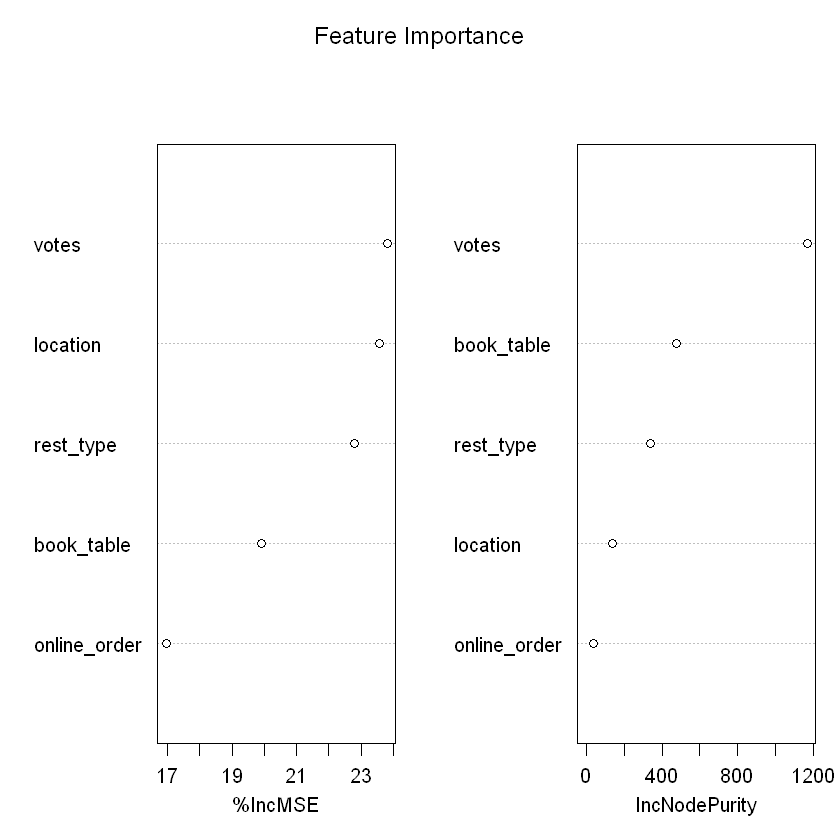

In [123]:
predictions <- predict(rf_model, newdata = test)

MAE <- mean(abs(predictions - test$rate))
RMSE <- sqrt(mean((predictions - test$rate)^2))

cat("Mean Absolute Error:", round(MAE, 3), "\n")
cat("Root Mean Square Error:", round(RMSE, 3), "\n")

varImpPlot(rf_model, main = "Feature Importance")


In [124]:
# This is a normalized MAE score, not classification accuracy.
mean_actual <- mean(test$rate)
relative_mae_score <- if (is.finite(mean_actual) && mean_actual != 0) {
  (1 - MAE / mean_actual) * 100
} else {
  NA_real_
}
cat("MAE-based relative score (not classification accuracy):", round(relative_mae_score, 2), "%\n")

MAE-based relative score (not classification accuracy): 93.24 %


In [125]:
# Predict for a sample using factor levels observed in the training data.
example <- data.frame(
  online_order = factor(levels(train$online_order)[1], levels = levels(train$online_order)),
  book_table = factor(levels(train$book_table)[1], levels = levels(train$book_table)),
  votes = stats::median(train$votes),
  location = factor(levels(train$location)[1], levels = levels(train$location)),
  rest_type = factor(levels(train$rest_type)[1], levels = levels(train$rest_type))
)

predicted_rating <- predict(rf_model, newdata = example)
cat("Predicted Rating for Example Restaurant:", round(predicted_rating, 2), "\n")

Predicted Rating for Example Restaurant: 3.65 


In [126]:
str(train)


'data.frame':	33333 obs. of  6 variables:
 $ rate        : num  4.1 4.1 3.8 3.7 3.8 3.8 3.6 4.6 4 4.2 ...
 $ online_order: Factor w/ 2 levels "No","Yes": 2 2 2 1 1 2 1 2 2 2 ...
 $ book_table  : Factor w/ 2 levels "No","Yes": 2 1 1 1 1 1 1 2 1 1 ...
 $ votes       : num  775 787 918 88 166 ...
 $ location    : Factor w/ 11 levels "10","26","27",..: 11 11 11 11 11 11 11 11 11 11 ...
 $ rest_type   : Factor w/ 11 levels "1","12","17",..: 4 4 11 9 4 4 4 11 3 3 ...


In [127]:
# Confirm the held-out rows use the same predictor columns as the training data.
stopifnot(identical(names(train), names(test)), nrow(test) > 0)
message("Train/test columns are consistent; held-out rows are ready for prediction.")

Train/test columns are consistent; held-out rows are ready for prediction.



In [128]:
levels(train$location)
levels(train$rest_type)


[1] "10"    "26"    "27"    "3"     "31"    "33"    "44"    "45"    "55"   
[10] "89"    "Other"

[1] "1"     "12"    "17"    "25"    "26"    "37"    "38"    "7"     "74"   
[10] "87"    "Other"

In [129]:
# Demonstrate prediction on a held-out restaurant, preserving its factor levels.
example_from_test <- test[1, setdiff(names(test), "rate"), drop = FALSE]
held_out_prediction <- predict(rf_model, newdata = example_from_test)
cat("Predicted rating for a held-out restaurant:", round(held_out_prediction, 2), "\n")

Predicted rating for a held-out restaurant: 3.83 


## Online Order Availability

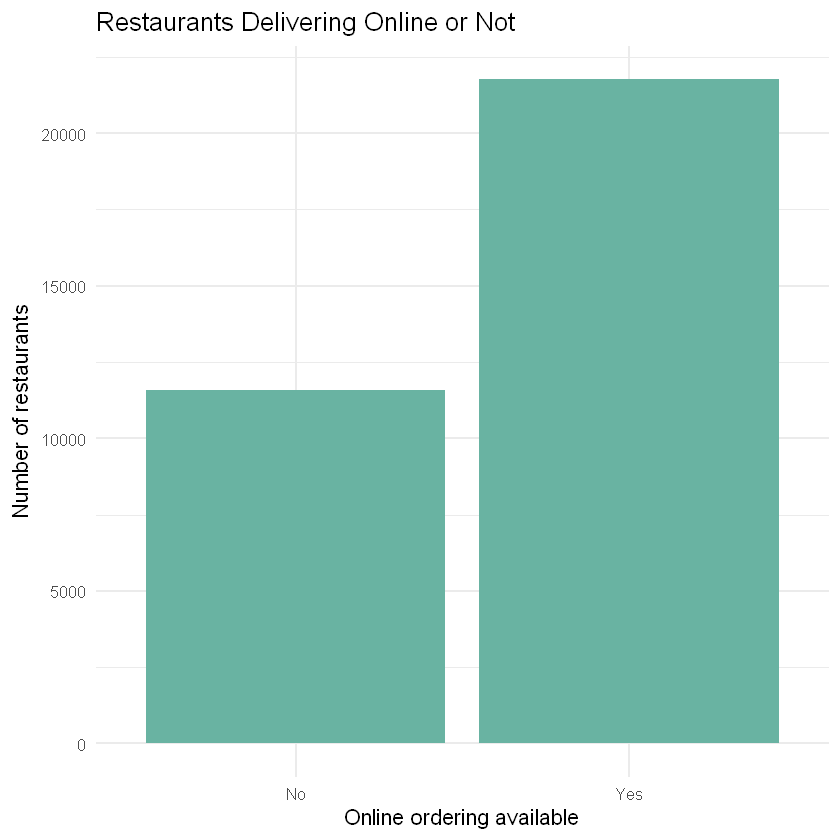

In [130]:
ggplot(train, aes(x = online_order)) +
  geom_bar(fill = "#69b3a2") +
  labs(title = "Restaurants Delivering Online or Not",
       x = "Online ordering available", y = "Number of restaurants") +
  theme_minimal(base_size = 13)

## Table Booking Availability

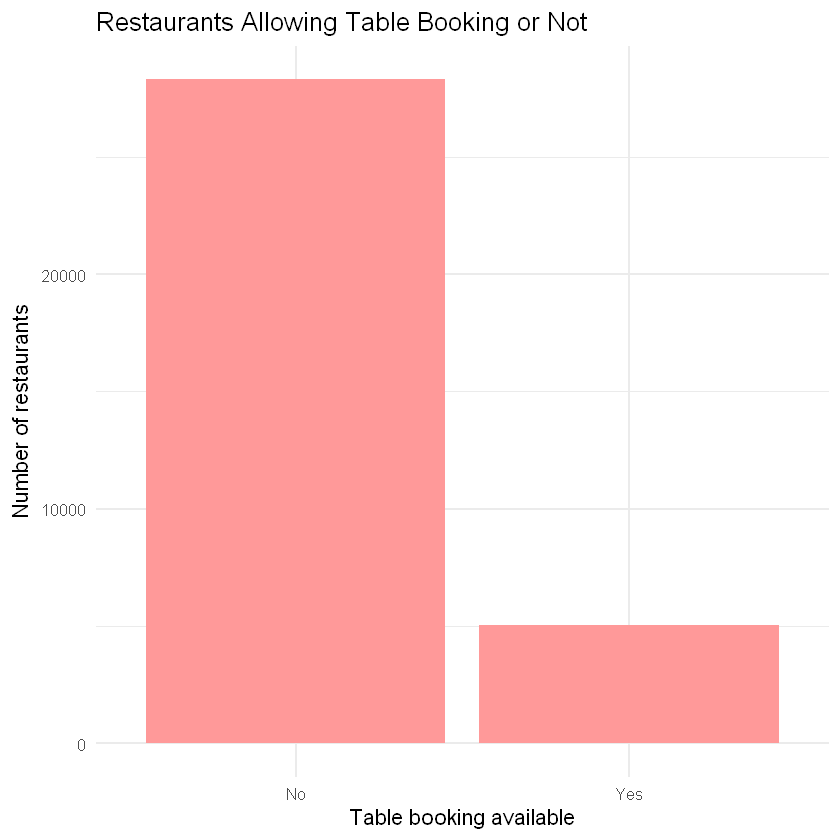

In [131]:
ggplot(train, aes(x = book_table)) +
  geom_bar(fill = "#ff9999") +
  labs(title = "Restaurants Allowing Table Booking or Not",
       x = "Table booking available", y = "Number of restaurants") +
  theme_minimal(base_size = 13)

## Best Location by Average Rating

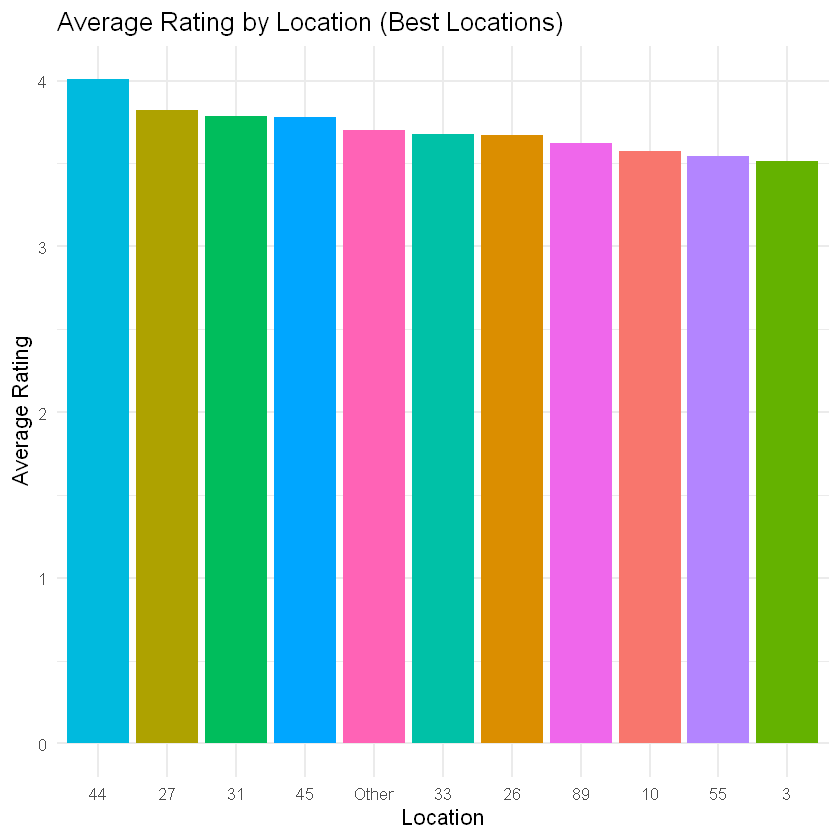

In [132]:
best_location <- train %>%
  group_by(location) %>%
  summarise(avg_rating = mean(rate, na.rm = TRUE)) %>%
  arrange(desc(avg_rating))

ggplot(best_location, aes(x = reorder(location, -avg_rating), y = avg_rating, fill = location)) +
  geom_bar(stat = "identity") +
  labs(title = "Average Rating by Location (Best Locations)",
       x = "Location",
       y = "Average Rating") +
  theme_minimal(base_size = 13) +
  theme(legend.position = "none")

## Relation Between Location and Rating

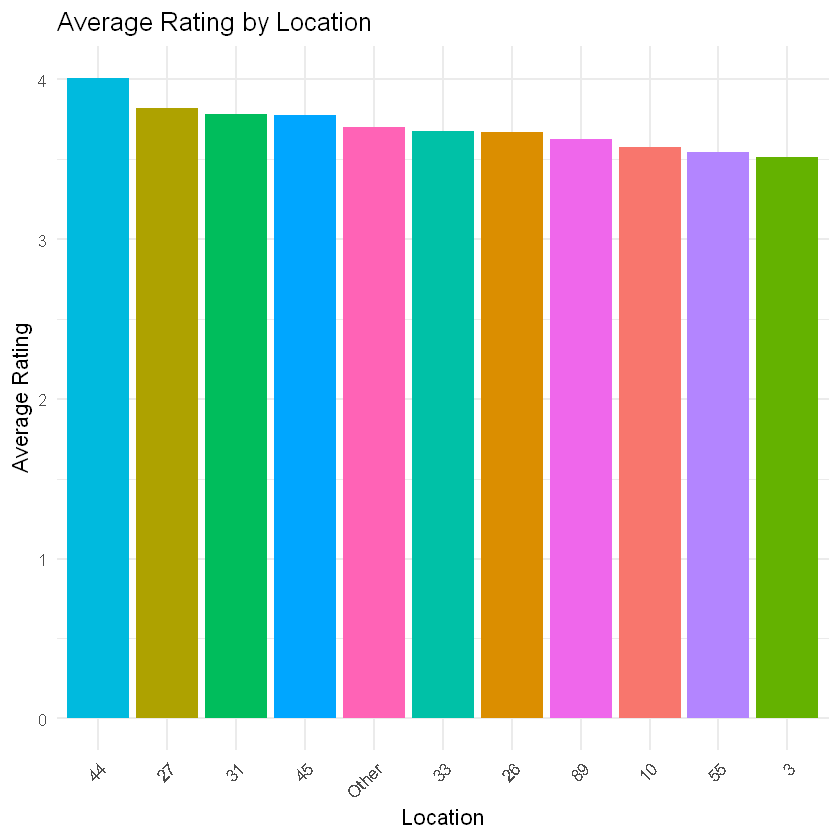

In [133]:
# Compute mean rating per location
location_avg <- train %>%
  group_by(location) %>%
  summarise(mean_rate = mean(rate, na.rm = TRUE)) %>%
  arrange(desc(mean_rate))

# Bar chart
ggplot(location_avg, aes(x = reorder(location, -mean_rate), y = mean_rate, fill = location)) +
  geom_col() +
  labs(title = "Average Rating by Location",
       x = "Location",
       y = "Average Rating") +
  theme_minimal(base_size = 13) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1)) +
  theme(legend.position = "none")


## Restaurant Type Distribution

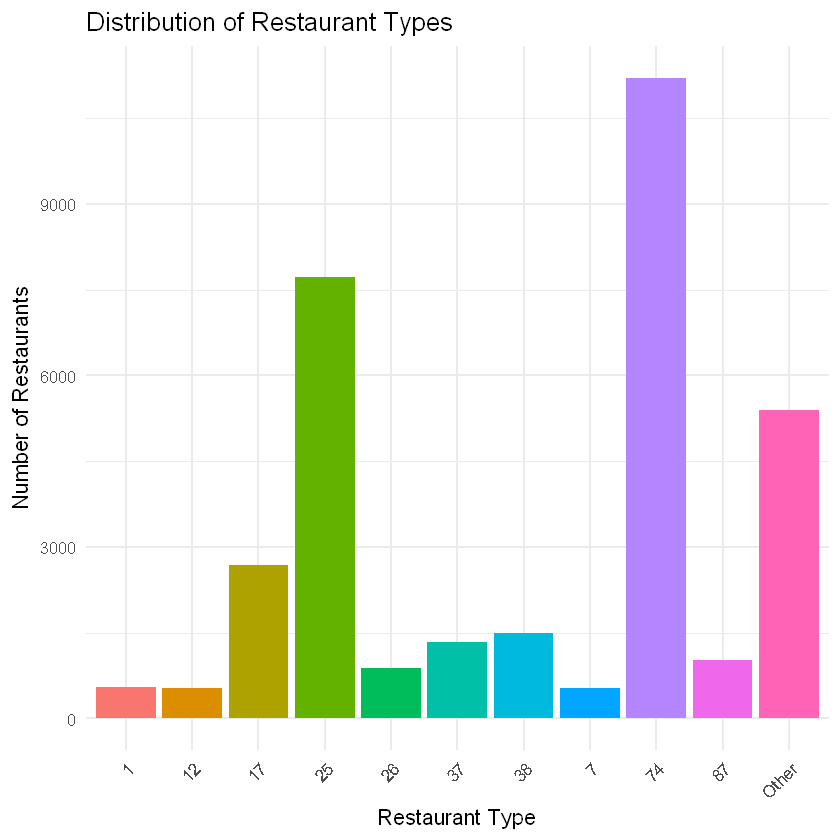

In [134]:
ggplot(train, aes(x = rest_type, fill = rest_type)) +
  geom_bar() +
  labs(title = "Distribution of Restaurant Types",
       x = "Restaurant Type",
       y = "Number of Restaurants") +
  theme_minimal(base_size = 13) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1)) +
  theme(legend.position = "none")

## Relation Between Type and Rating

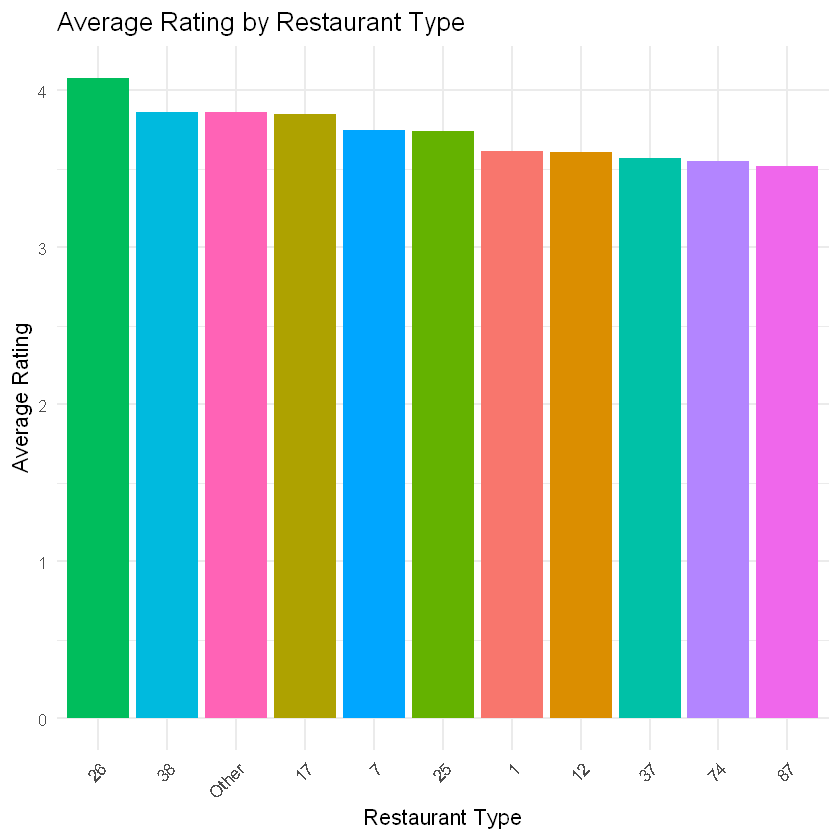

In [135]:
# Compute mean rating per restaurant type
type_avg <- train %>%
  group_by(rest_type) %>%
  summarise(mean_rate = mean(rate, na.rm = TRUE)) %>%
  arrange(desc(mean_rate))

# Bar chart
ggplot(type_avg, aes(x = reorder(rest_type, -mean_rate), y = mean_rate, fill = rest_type)) +
  geom_col() +
  labs(title = "Average Rating by Restaurant Type",
       x = "Restaurant Type",
       y = "Average Rating") +
  theme_minimal(base_size = 13) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1)) +
  theme(legend.position = "none")

## Number of Restaurants per Location

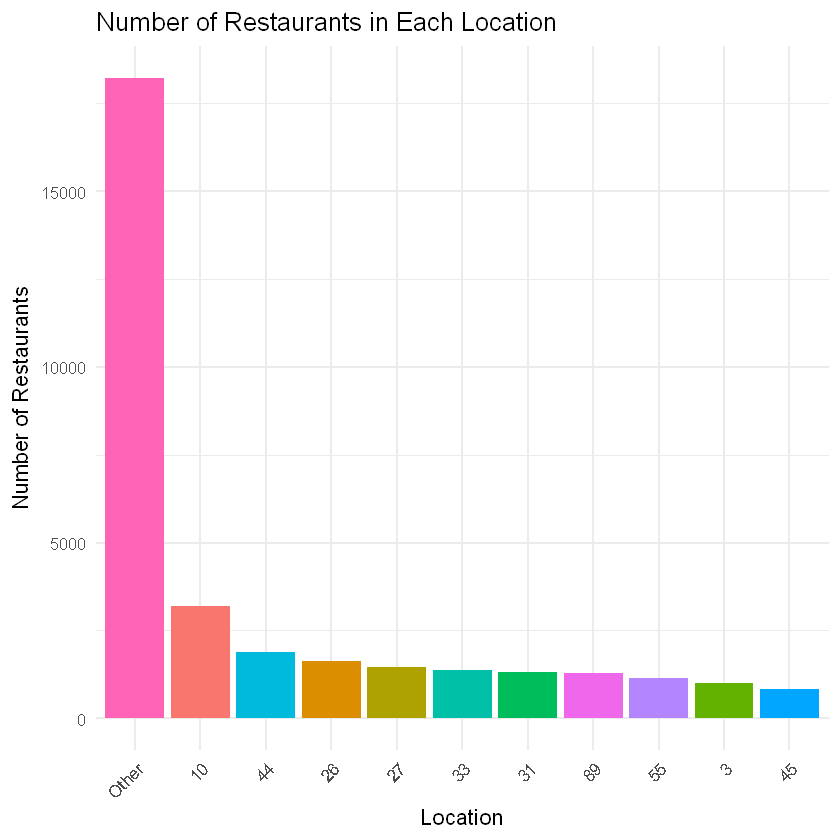

In [136]:
location_count <- train %>%
  group_by(location) %>%
  summarise(restaurant_count = n())

ggplot(location_count, aes(x = reorder(location, -restaurant_count), y = restaurant_count, fill = location)) +
  geom_bar(stat = "identity") +
  labs(title = "Number of Restaurants in Each Location",
       x = "Location",
       y = "Number of Restaurants") +
  theme_minimal(base_size = 13) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1)) +
  theme(legend.position = "none")

In [137]:
# Factor levels are category labels, not manually assigned numeric codes.
location_table <- data.frame(Location = levels(train$location))
print(location_table)

   Location
1        10
2        26
3        27
4         3
5        31
6        33
7        44
8        45
9        55
10       89
11    Other


In [138]:
# Factor levels are category labels, not manually assigned numeric codes.
rest_type_table <- data.frame(Restaurant_Type = levels(train$rest_type))
print(rest_type_table)

   Restaurant_Type
1                1
2               12
3               17
4               25
5               26
6               37
7               38
8                7
9               74
10              87
11           Other


In [139]:
# List files in the current R working directory.
list.files()

[1] "Copy_of_Zomato_analysis.backup_20261020_1522.ipynb"
[2] "Copy_of_Zomato_analysis.ipynb"                     
[3] "Rplots.pdf"                                        
[4] "Rtmp"                                              
[5] "zomato.csv"

## NOVELTY FEATURE 1: Reliability-Adjusted Restaurant Rankings

This is a **proposed reliability-aware ranking method**, not a proven improvement. The source has repeated listings for some physical outlets, so rows are grouped by normalized restaurant name, address, and location. Because the file has no timestamp and repeated rows can disagree, vote counts are not summed: each outlet uses the rating from its highest-vote listing (ties are averaged) and that listing's vote count. This avoids counting repeated listings as independent votes.

The prior `C` is calculated from the resulting outlet-level ratings. The configurable threshold `m` is the outlet-level 75th percentile of nonnegative vote counts (minimum 1), so the prior increasingly moderates ratings with fewer votes. Missing or invalid vote counts contribute zero votes; a zero-vote outlet receives the prior score.

In [140]:
# NOVELTY FEATURE 1: Reliability-Adjusted Restaurant Rankings
novelty1_required_columns <- c("name", "address", "location", "rate", "votes")
novelty1_raw <- as.data.frame(readr::read_csv(
  dataset_path, show_col_types = FALSE, name_repair = "minimal"
))
names(novelty1_raw) <- make.names(names(novelty1_raw), unique = TRUE)
novelty1_missing_columns <- setdiff(novelty1_required_columns, names(novelty1_raw))
if (length(novelty1_missing_columns) > 0) {
  stop("Ranking analysis requires columns: ", paste(novelty1_missing_columns, collapse = ", "))
}

novelty1_rate_text <- trimws(as.character(novelty1_raw$rate))
novelty1_rate_text <- sub("\\s*/\\s*5\\s*$", "", novelty1_rate_text)
novelty1_rate_text[toupper(novelty1_rate_text) %in% c("", "NEW", "-", "NA", "N/A")] <- NA_character_
novelty1_rate <- suppressWarnings(as.numeric(novelty1_rate_text))
novelty1_valid_rate <- is.finite(novelty1_rate) & novelty1_rate >= 0 & novelty1_rate <= 5
novelty1_vote_text <- gsub(",", "", trimws(as.character(novelty1_raw$votes)), fixed = TRUE)
novelty1_vote_text[novelty1_vote_text == ""] <- NA_character_
novelty1_votes <- suppressWarnings(as.numeric(novelty1_vote_text))
novelty1_valid_votes <- is.finite(novelty1_votes) & novelty1_votes >= 0

novelty1_source <- novelty1_raw[novelty1_valid_rate, novelty1_required_columns, drop = FALSE]
novelty1_source$rate <- novelty1_rate[novelty1_valid_rate]
novelty1_source$votes <- novelty1_votes[novelty1_valid_rate]
novelty1_source$votes_for_group <- ifelse(
  is.finite(novelty1_source$votes) & novelty1_source$votes >= 0,
  novelty1_source$votes, 0
)
novelty1_source$row_id <- seq_len(nrow(novelty1_source))
for (novelty1_col in c("name", "address", "location")) {
  novelty1_value <- tolower(gsub("\\s+", " ", trimws(as.character(novelty1_source[[novelty1_col]]))) )
  novelty1_missing <- is.na(novelty1_value) | novelty1_value == ""
  novelty1_value[novelty1_missing] <- paste0("<missing-", novelty1_source$row_id[novelty1_missing], ">")
  novelty1_source[[paste0(novelty1_col, "_key")]] <- novelty1_value
}

novelty1_restaurants <- novelty1_source %>%
  group_by(name_key, address_key, location_key) %>%
  mutate(group_listing_count = n()) %>%
  filter(votes_for_group == max(votes_for_group)) %>%
  summarise(
    name = first(name), address = first(address), location = first(location),
    rating = mean(rate), votes = max(votes_for_group),
    source_listings = first(group_listing_count),
    .groups = "drop"
  ) %>%
  mutate(restaurant_label = paste(name, location, address, sep = " | "))
if (nrow(novelty1_restaurants) == 0) stop("No valid rated restaurants are available for ranking.")

novelty1_C <- mean(novelty1_restaurants$rating)
novelty1_m <- max(1, as.numeric(stats::quantile(
  novelty1_restaurants$votes, probs = 0.75, na.rm = TRUE, names = FALSE
)))
novelty1_rankings <- novelty1_restaurants %>%
  mutate(
    weighted_rating = (votes / (votes + novelty1_m)) * rating +
      (novelty1_m / (votes + novelty1_m)) * novelty1_C,
    ordinary_rank = rank(-rating, ties.method = "min"),
    weighted_rank = rank(-weighted_rating, ties.method = "min"),
    rank_change = weighted_rank - ordinary_rank
  )

cat("Rated source listings:", nrow(novelty1_source), "\n")
cat("Unique outlet groups:", nrow(novelty1_restaurants), "\n")
cat("Source rows with missing/invalid/negative votes treated as zero:",
    sum(!novelty1_valid_votes[novelty1_valid_rate]), "\n")
cat("C (mean outlet rating):", round(novelty1_C, 4),
    " | m (75th percentile votes, minimum 1):", round(novelty1_m, 2), "\n")
print(novelty1_rankings %>%
  filter(ordinary_rank <= 15 | weighted_rank <= 15) %>%
  arrange(weighted_rank, ordinary_rank) %>%
  select(name, location, rating, votes, weighted_rating, ordinary_rank, weighted_rank, rank_change),
  n = 30)


Rated source listings: 41665 
Unique outlet groups: 9521 
Source rows with missing/invalid/negative votes treated as zero: 0 
C (mean outlet rating): 3.6263  | m (75th percentile votes, minimum 1): 189 
# A tibble: 25 × 8
   name        location rating votes weighted_rating ordinary_rank weighted_rank
   <chr>       <chr>     <dbl> <dbl>           <dbl>         <int>         <int>
 1 "Byg Brews… Sarjapu…    4.9 16832            4.89             1             1
 2 "AB's - Ab… BTM         4.9  6490            4.86             1             2
 3 "Flechazo"  Whitefi…    4.9  3004            4.82             1             3
 4 "Asia Kitc… Koraman…    4.9  2256            4.80             1             4
 5 "Milano Ic… Indiran…    4.9  2090            4.79             1             5
 6 "Punjab Gr… Mallesh…    4.9  1985            4.79             1             6
 7 "AB's - Ab… Maratha…    4.8 12121            4.78            10             7
 8 "Belgian W… Brigade…    4.9  1750            4

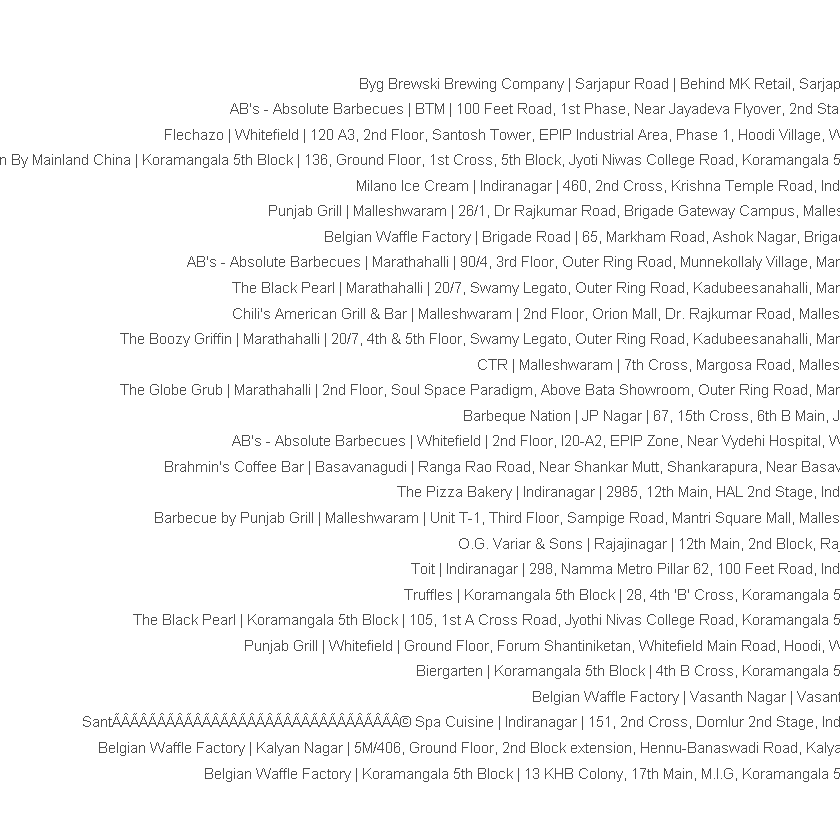

In [141]:
# NOVELTY FEATURE 1: Reliability-Adjusted Restaurant Rankings
novelty1_plot_data <- novelty1_rankings %>%
  filter(ordinary_rank <= 20 | weighted_rank <= 20) %>%
  select(restaurant_label, ordinary_rank, weighted_rank) %>%
  tidyr::pivot_longer(
    cols = c(ordinary_rank, weighted_rank),
    names_to = "rank_method", values_to = "rank"
  ) %>%
  mutate(rank_method = dplyr::recode(
    rank_method, ordinary_rank = "Ordinary rating", weighted_rank = "Weighted rating"
  ))

ggplot(novelty1_plot_data, aes(x = rank, y = reorder(restaurant_label, -rank), color = rank_method)) +
  geom_line(aes(group = restaurant_label), color = "grey70", linewidth = 0.5) +
  geom_point(size = 2) +
  scale_x_reverse() +
  labs(
    title = "Proposed reliability-aware ranking: top-20 rank changes",
    subtitle = "Lower rank number is better; only outlets in either top 20 are shown",
    x = "Rank", y = "Restaurant outlet", color = "Ranking method"
  ) +
  theme_minimal(base_size = 11)


### Ranking Sensitivity and Robustness

The following analysis keeps the existing outlet grouping and highest-vote-listing aggregation. It holds the outlet-level prior `C` and the ranked outlet dataset fixed while varying `m` across valid, distinct 25th, 50th, 75th, and 90th percentiles of positive outlet vote counts. Spearman correlation uses average ranks for ties. Top-20 membership uses deterministic sorting by score and then the grouped outlet identity; if fewer than 20 eligible outlets exist, the available number is used. For a descriptive stability label only, rankings are called stable if every threshold has Spearman correlation at least 0.95 and top-k overlap at least 80%; these are practical reporting cutoffs, not statistical tests. An alternative aggregation that averages all duplicate-listing ratings is reported separately and does not replace the primary highest-vote method.

In [ ]:
# NOVELTY FEATURE 1: Reliability-Adjusted Restaurant Rankings
novelty1_sensitivity_source <- novelty1_source
novelty1_sensitivity_primary <- novelty1_sensitivity_source %>%
  group_by(name_key, address_key, location_key) %>%
  filter(votes_for_group == max(votes_for_group)) %>%
  summarise(
    name = first(name), location = first(location), address = first(address),
    rating = mean(rate), votes = max(votes_for_group),
    .groups = "drop"
  ) %>%
  mutate(
    restaurant_id = paste(name_key, address_key, location_key, sep = "\u001f"),
    restaurant_label = paste(name, "@", location, "|", address, sep = " ")
  )
if (!isTRUE(all.equal(nrow(novelty1_sensitivity_primary), nrow(novelty1_restaurants))) ||
    !isTRUE(all.equal(sort(novelty1_sensitivity_primary$rating), sort(novelty1_restaurants$rating))) ||
    !isTRUE(all.equal(sort(novelty1_sensitivity_primary$votes), sort(novelty1_restaurants$votes)))) {
  stop("Sensitivity aggregation does not match the primary highest-vote aggregation.")
}
novelty1_sensitivity_k <- min(20L, nrow(novelty1_sensitivity_primary))
if (novelty1_sensitivity_k < 20L) {
  message("Fewer than 20 eligible outlets; top-k uses all ", novelty1_sensitivity_k, " outlets.")
}
novelty1_positive_votes <- novelty1_sensitivity_primary$votes[
  is.finite(novelty1_sensitivity_primary$votes) & novelty1_sensitivity_primary$votes > 0
]
if (length(novelty1_positive_votes) == 0) stop("No positive outlet vote counts are available for sensitivity thresholds.")
novelty1_percentile_values <- stats::quantile(
  novelty1_positive_votes, probs = c(0.25, 0.50, 0.75, 0.90),
  na.rm = TRUE, names = FALSE, type = 7
)
novelty1_threshold_candidates <- data.frame(
  percentile = c("25th", "50th", "75th", "90th"),
  threshold = pmax(1, as.numeric(novelty1_percentile_values)),
  stringsAsFactors = FALSE
)
novelty1_threshold_grid <- novelty1_threshold_candidates %>%
  filter(is.finite(threshold), threshold > 0) %>%
  distinct(threshold, .keep_all = TRUE)
if (nrow(novelty1_threshold_grid) == 0) stop("No valid distinct positive vote thresholds were produced.")
if (nrow(novelty1_threshold_grid) < nrow(novelty1_threshold_candidates)) {
  message("Duplicate percentile thresholds were collapsed; only valid distinct thresholds are compared.")
}

novelty1_sensitivity_rankings <- vector("list", nrow(novelty1_threshold_grid))
novelty1_sensitivity_rows <- vector("list", nrow(novelty1_threshold_grid))
novelty1_ordinary_order <- novelty1_sensitivity_primary %>%
  arrange(desc(rating), restaurant_id)
novelty1_ordinary_top_ids <- head(novelty1_ordinary_order$restaurant_id, novelty1_sensitivity_k)
novelty1_ordinary_rank_values <- rank(-novelty1_sensitivity_primary$rating, ties.method = "average")

for (novelty1_i in seq_len(nrow(novelty1_threshold_grid))) {
  novelty1_threshold <- novelty1_threshold_grid$threshold[[novelty1_i]]
  novelty1_current <- novelty1_sensitivity_primary %>%
    mutate(
      prior_rating = novelty1_C,
      vote_threshold = novelty1_threshold,
      weighted_rating = (votes / (votes + vote_threshold)) * rating +
        (vote_threshold / (votes + vote_threshold)) * prior_rating,
      ordinary_rank = novelty1_ordinary_rank_values,
      weighted_rank = rank(-weighted_rating, ties.method = "average"),
      rank_change = weighted_rank - ordinary_rank
    )
  novelty1_weighted_order <- novelty1_current %>% arrange(desc(weighted_rating), restaurant_id)
  novelty1_weighted_top_ids <- head(novelty1_weighted_order$restaurant_id, novelty1_sensitivity_k)
  novelty1_entered_ids <- setdiff(novelty1_weighted_top_ids, novelty1_ordinary_top_ids)
  novelty1_left_ids <- setdiff(novelty1_ordinary_top_ids, novelty1_weighted_top_ids)
  novelty1_entered_labels <- novelty1_current$restaurant_label[
    match(novelty1_entered_ids, novelty1_current$restaurant_id)
  ]
  novelty1_left_labels <- novelty1_current$restaurant_label[
    match(novelty1_left_ids, novelty1_current$restaurant_id)
  ]
  novelty1_rho <- suppressWarnings(stats::cor(
    novelty1_current$ordinary_rank, novelty1_current$weighted_rank,
    method = "spearman", use = "complete.obs"
  ))
  novelty1_overlap <- length(intersect(novelty1_ordinary_top_ids, novelty1_weighted_top_ids))
  novelty1_sensitivity_rows[[novelty1_i]] <- data.frame(
    percentile = novelty1_threshold_grid$percentile[[novelty1_i]],
    vote_threshold_m = novelty1_threshold,
    spearman_rho = novelty1_rho,
    top_k = novelty1_sensitivity_k,
    top_k_overlap = novelty1_overlap,
    top_k_overlap_percent = 100 * novelty1_overlap / novelty1_sensitivity_k,
    entered_top_k = paste(novelty1_entered_labels, collapse = "; "),
    left_top_k = paste(novelty1_left_labels, collapse = "; "),
    mean_absolute_rank_change = mean(abs(novelty1_current$rank_change)),
    maximum_absolute_rank_change = max(abs(novelty1_current$rank_change)),
    stringsAsFactors = FALSE
  )
  novelty1_sensitivity_rankings[[novelty1_i]] <- novelty1_current
}
novelty1_sensitivity_results <- dplyr::bind_rows(novelty1_sensitivity_rows)
novelty1_rank_changes <- dplyr::bind_rows(lapply(seq_along(novelty1_sensitivity_rankings), function(i) {
  novelty1_sensitivity_rankings[[i]] %>%
    transmute(
      percentile = novelty1_threshold_grid$percentile[[i]],
      vote_threshold_m = novelty1_threshold_grid$threshold[[i]],
      restaurant_id, restaurant_label, ordinary_rank, weighted_rank, rank_change
    )
}))
cat("Fixed prior C:", round(novelty1_C, 4), " | outlets:", nrow(novelty1_sensitivity_primary),
    " | top-k:", novelty1_sensitivity_k, "\n")
print(novelty1_sensitivity_results, row.names = FALSE)

novelty1_top_k_change_detail <- dplyr::bind_rows(lapply(seq_along(novelty1_sensitivity_rankings), function(i) {
  novelty1_current <- novelty1_sensitivity_rankings[[i]]
  novelty1_weighted_top <- novelty1_current %>%
    arrange(desc(weighted_rating), restaurant_id) %>%
    slice_head(n = novelty1_sensitivity_k) %>%
    pull(restaurant_id)
  novelty1_entered <- setdiff(novelty1_weighted_top, novelty1_ordinary_top_ids)
  novelty1_left <- setdiff(novelty1_ordinary_top_ids, novelty1_weighted_top)
  novelty1_change_rows <- dplyr::bind_rows(
    novelty1_current %>% filter(restaurant_id %in% novelty1_entered) %>% mutate(change = "Entered weighted top-k"),
    novelty1_current %>% filter(restaurant_id %in% novelty1_left) %>% mutate(change = "Left weighted top-k")
  )
  novelty1_change_rows %>% transmute(
    percentile = novelty1_threshold_grid$percentile[[i]],
    vote_threshold_m = novelty1_threshold_grid$threshold[[i]],
    change, name, location, ordinary_rank, weighted_rank, rank_change
  )
})) %>% arrange(vote_threshold_m, change, weighted_rank)
cat("Top-k membership changes by threshold (deterministic identity-based tie breaks):\n")
print(novelty1_top_k_change_detail, n = Inf, width = Inf)

novelty1_rank_change_examples <- novelty1_rank_changes %>%
  filter(percentile == novelty1_threshold_grid$percentile[[nrow(novelty1_threshold_grid)]]) %>%
  arrange(desc(abs(rank_change))) %>%
  slice_head(n = 10) %>%
  select(percentile, restaurant_label, ordinary_rank, weighted_rank, rank_change)
cat("Ten largest individual rank changes at the highest valid threshold:\n")
print(novelty1_rank_change_examples, n = Inf, width = Inf)

novelty1_sensitivity_plot_data <- novelty1_sensitivity_results %>%
  select(percentile, vote_threshold_m, spearman_rho, top_k_overlap_percent) %>%
  tidyr::pivot_longer(
    cols = c(spearman_rho, top_k_overlap_percent),
    names_to = "stability_measure", values_to = "value"
  ) %>%
  mutate(stability_measure = dplyr::recode(
    stability_measure,
    spearman_rho = "Spearman rank correlation",
    top_k_overlap_percent = "Top-k overlap (%)"
  ))
print(ggplot(novelty1_sensitivity_plot_data,
             aes(x = reorder(percentile, vote_threshold_m), y = value, group = 1)) +
  geom_line(color = "#4C78A8", linewidth = 0.8) +
  geom_point(color = "#E45756", size = 2.5) +
  facet_wrap(~stability_measure, scales = "free_y") +
  labs(title = "Ranking stability across vote thresholds",
       subtitle = "The same outlet data and rating prior are used at every threshold",
       x = "Positive vote-count percentile used for m", y = "Stability measure") +
  theme_minimal(base_size = 12))

novelty1_min_rho <- min(novelty1_sensitivity_results$spearman_rho, na.rm = TRUE)
novelty1_min_overlap <- min(novelty1_sensitivity_results$top_k_overlap_percent, na.rm = TRUE)
novelty1_stability_label <- if (novelty1_min_rho >= 0.95 && novelty1_min_overlap >= 80) {
  "stable under the stated descriptive criteria"
} else {
  "sensitive under the stated descriptive criteria"
}
cat("Interpretation: the rankings are", novelty1_stability_label,
    "(minimum Spearman rho =", round(novelty1_min_rho, 4),
    "; minimum top-k overlap =", round(novelty1_min_overlap, 1), "%).\n")
cat("As m increases, low-vote ratings are pulled more strongly toward the fixed prior C;",
    "read the table for the observed direction and magnitude rather than assuming improvement.\n")

# Separate alternative-aggregation check: average ratings over all duplicate listings, retain maximum vote count.
novelty1_alternative_aggregation <- novelty1_sensitivity_source %>%
  group_by(name_key, address_key, location_key) %>%
  summarise(
    name = first(name), location = first(location), address = first(address),
    rating = mean(rate), votes = max(votes_for_group), .groups = "drop"
  ) %>%
  mutate(
    restaurant_id = paste(name_key, address_key, location_key, sep = "\u001f"),
    restaurant_label = paste(name, "@", location, "|", address, sep = " "),
    weighted_rating = (votes / (votes + novelty1_m)) * rating +
      (novelty1_m / (votes + novelty1_m)) * novelty1_C
  )
novelty1_alt_ordinary <- novelty1_alternative_aggregation %>% arrange(desc(rating), restaurant_id)
novelty1_alt_weighted <- novelty1_alternative_aggregation %>% arrange(desc(weighted_rating), restaurant_id)
novelty1_alt_k <- min(20L, nrow(novelty1_alternative_aggregation))
novelty1_primary_weighted_order <- novelty1_sensitivity_primary %>%
  mutate(
    primary_weighted_rating = (votes / (votes + novelty1_m)) * rating +
      (novelty1_m / (votes + novelty1_m)) * novelty1_C,
    primary_weighted_rank = rank(-primary_weighted_rating, ties.method = "average")
  ) %>%
  arrange(desc(primary_weighted_rating), restaurant_id)
novelty1_alt_primary_top <- head(novelty1_primary_weighted_order$restaurant_id, novelty1_alt_k)
novelty1_alt_method_top <- head(novelty1_alt_weighted$restaurant_id, novelty1_alt_k)
novelty1_alt_rank_pairs <- novelty1_primary_weighted_order %>%
  select(restaurant_id, primary_weighted_rank) %>%
  inner_join(
    novelty1_alternative_aggregation %>%
      mutate(alternative_weighted_rank = rank(-weighted_rating, ties.method = "average")) %>%
      select(restaurant_id, alternative_weighted_rank),
    by = "restaurant_id"
  )
novelty1_alternative_aggregation_result <- data.frame(
  method = "Average ratings over all duplicate listings; maximum listing vote count",
  prior_C = novelty1_C, threshold_m = novelty1_m,
  outlet_count = nrow(novelty1_alternative_aggregation), top_k = novelty1_alt_k,
  top_k_overlap_with_primary_weighted = length(intersect(novelty1_alt_primary_top, novelty1_alt_method_top)),
  spearman_vs_primary_weighted = stats::cor(
    novelty1_alt_rank_pairs$primary_weighted_rank,
    novelty1_alt_rank_pairs$alternative_weighted_rank,
    method = "spearman"
  ),
  stringsAsFactors = FALSE
)
cat("Alternative aggregation sensitivity check (does not replace the primary aggregation):\n")
print(novelty1_alternative_aggregation_result, row.names = FALSE)


## NOVELTY FEATURE 2: Comparative Rating Prediction Models

The target is the existing `rate` field and the predictor set matches the original Random Forest (`online_order`, `book_table`, `votes`, `location`, and `rest_type`). A fresh copy of the CSV is used to rebuild these features without the original full-data category collapsing. The notebook's existing `trainIndex` is reused and checked against the raw cleaned target, so all comparison models share its 80/20 split. Category grouping and unknown-level handling are learned from the training partition only.

The comparison Random Forest is separately fitted with the existing formula and 200-tree specification; the original `rf_model`, its predictions, and its reported metrics remain unchanged. Five-fold cross-validation is confined to the training partition and is used for stability, not test-set tuning. Predictive R-squared is defined as `1 - SSE / SST`. Gradient Boosting uses the `gbm` package when installed; it is reported as unavailable rather than replaced if the package is missing.

In [142]:
# NOVELTY FEATURE 2: Comparative Rating Prediction Models
novelty2_required_packages <- c("gbm")
novelty2_missing_packages <- novelty2_required_packages[
  !vapply(novelty2_required_packages, requireNamespace, logical(1), quietly = TRUE)
]
novelty2_gbm_available <- length(novelty2_missing_packages) == 0
if (!novelty2_gbm_available) {
  message(
    "Gradient Boosting is unavailable: install the missing package with install.packages(\"gbm\"). " ,
    "No substitute model will be used."
  )
} else {
  message("Gradient Boosting package gbm is available.")
}


Gradient Boosting is unavailable: install the missing package with install.packages("gbm"). No substitute model will be used.



In [ ]:
# NOVELTY FEATURE 2: Comparative Rating Prediction Models
novelty2_raw <- as.data.frame(readr::read_csv(
  dataset_path, show_col_types = FALSE, name_repair = "minimal"
))
names(novelty2_raw) <- make.names(names(novelty2_raw), unique = TRUE)
novelty2_columns <- c("rate", "online_order", "book_table", "votes", "location", "rest_type")
novelty2_missing_columns <- setdiff(novelty2_columns, names(novelty2_raw))
if (length(novelty2_missing_columns) > 0) {
  stop("Model comparison requires columns: ", paste(novelty2_missing_columns, collapse = ", "))
}

novelty2_rate_text <- trimws(as.character(novelty2_raw$rate))
novelty2_rate_text <- sub("\\s*/\\s*5\\s*$", "", novelty2_rate_text)
novelty2_rate_text[toupper(novelty2_rate_text) %in% c("", "NEW", "-", "NA", "N/A")] <- NA_character_
novelty2_rate <- suppressWarnings(as.numeric(novelty2_rate_text))
novelty2_vote_text <- gsub(",", "", trimws(as.character(novelty2_raw$votes)), fixed = TRUE)
novelty2_vote_text[novelty2_vote_text == ""] <- NA_character_
novelty2_votes <- suppressWarnings(as.numeric(novelty2_vote_text))
novelty2_data <- data.frame(
  rate = novelty2_rate, votes = novelty2_votes,
  online_order = trimws(as.character(novelty2_raw$online_order)),
  book_table = trimws(as.character(novelty2_raw$book_table)),
  location = trimws(as.character(novelty2_raw$location)),
  rest_type = trimws(as.character(novelty2_raw$rest_type)),
  stringsAsFactors = FALSE
)
for (novelty2_col in c("location", "rest_type")) {
  novelty2_data[[novelty2_col]][is.na(novelty2_data[[novelty2_col]]) |
    novelty2_data[[novelty2_col]] == ""] <- "Other"
}
novelty2_complete <- is.finite(novelty2_data$rate) & novelty2_data$rate >= 0 &
  novelty2_data$rate <= 5 & is.finite(novelty2_data$votes) & novelty2_data$votes >= 0 &
  !is.na(novelty2_data$online_order) & novelty2_data$online_order != "" &
  !is.na(novelty2_data$book_table) & novelty2_data$book_table != ""
novelty2_data <- novelty2_data[novelty2_complete, , drop = FALSE]
if (nrow(novelty2_data) != nrow(zomato_model) ||
    !isTRUE(all.equal(novelty2_data$rate, as.numeric(zomato_model$rate)))) {
  stop("Fresh comparison rows do not align with the existing cleaned model rows/target.")
}
novelty2_train_rows <- as.integer(trainIndex)
if (length(novelty2_train_rows) == 0 || any(novelty2_train_rows < 1 | novelty2_train_rows > nrow(novelty2_data))) {
  stop("The existing trainIndex is invalid for the comparison data.")
}
novelty2_train_raw <- novelty2_data[novelty2_train_rows, , drop = FALSE]
novelty2_test_raw <- novelty2_data[-novelty2_train_rows, , drop = FALSE]

novelty2_prepare_features <- function(analysis_data, assessment_data) {
  analysis_data <- as.data.frame(analysis_data)
  assessment_data <- as.data.frame(assessment_data)
  for (novelty2_col in c("online_order", "book_table", "location", "rest_type")) {
    analysis_value <- trimws(as.character(analysis_data[[novelty2_col]]))
    assessment_value <- trimws(as.character(assessment_data[[novelty2_col]]))
    analysis_value[is.na(analysis_value) | analysis_value == ""] <- NA_character_
    assessment_value[is.na(assessment_value) | assessment_value == ""] <- NA_character_
    analysis_mode <- names(sort(table(analysis_value), decreasing = TRUE))[1]
    if (novelty2_col %in% c("location", "rest_type")) {
      analysis_frequency <- sort(table(analysis_value), decreasing = TRUE)
      novelty2_keep <- names(analysis_frequency)[seq_len(min(10, length(analysis_frequency)))]
      analysis_value[is.na(analysis_value) | !analysis_value %in% novelty2_keep] <- "Other"
      assessment_value[is.na(assessment_value) | !assessment_value %in% novelty2_keep] <- "Other"
      if (!any(analysis_value == "Other")) {
        assessment_value[assessment_value == "Other"] <- analysis_mode
      }
    } else {
      analysis_value[is.na(analysis_value)] <- "Other"
      novelty2_known <- unique(analysis_value)
      assessment_value[is.na(assessment_value) | !assessment_value %in% novelty2_known] <- analysis_mode
    }
    novelty2_levels <- unique(analysis_value)
    assessment_value[!assessment_value %in% novelty2_levels] <- analysis_mode
    analysis_data[[novelty2_col]] <- factor(analysis_value, levels = novelty2_levels)
    assessment_data[[novelty2_col]] <- factor(assessment_value, levels = novelty2_levels)
  }
  list(analysis = analysis_data, assessment = assessment_data)
}

# Tune GBM parameters using only the supplied analysis partition; preprocessing is refit inside each fold.
novelty2_tune_gbm <- function(analysis_raw, seed, folds = 3L) {
  if (nrow(analysis_raw) < 6L) stop("At least six training rows are required for GBM cross-validation.")
  folds <- min(as.integer(folds), nrow(analysis_raw))
  novelty2_gbm_grid <- expand.grid(
    n.trees = c(200L, 500L),
    interaction.depth = c(1L, 2L),
    shrinkage = c(0.03, 0.05),
    KEEP.OUT.ATTRS = FALSE
  )
  set.seed(seed)
  novelty2_gbm_fold_indices <- caret::createFolds(
    analysis_raw$rate, k = folds, list = TRUE, returnTrain = FALSE
  )
  novelty2_gbm_tuning_rows <- vector("list", nrow(novelty2_gbm_grid) * folds)
  novelty2_gbm_row <- 1L
  for (novelty2_grid_row in seq_len(nrow(novelty2_gbm_grid))) {
    novelty2_params <- novelty2_gbm_grid[novelty2_grid_row, , drop = FALSE]
    for (novelty2_fold in seq_along(novelty2_gbm_fold_indices)) {
      novelty2_valid_index <- novelty2_gbm_fold_indices[[novelty2_fold]]
      novelty2_fold_prepared <- novelty2_prepare_features(
        analysis_raw[-novelty2_valid_index, , drop = FALSE],
        analysis_raw[novelty2_valid_index, , drop = FALSE]
      )
      set.seed(seed + novelty2_grid_row * 100L + novelty2_fold)
      novelty2_fold_model <- gbm::gbm(
        rate ~ ., data = novelty2_fold_prepared$analysis,
        distribution = "gaussian", n.trees = novelty2_params$n.trees,
        interaction.depth = novelty2_params$interaction.depth,
        shrinkage = novelty2_params$shrinkage,
        n.minobsinnode = 10, bag.fraction = 0.8,
        train.fraction = 1, verbose = FALSE
      )
      novelty2_fold_prediction <- as.numeric(stats::predict(
        novelty2_fold_model, newdata = novelty2_fold_prepared$assessment,
        n.trees = novelty2_params$n.trees, type = "response"
      ))
      novelty2_gbm_tuning_rows[[novelty2_gbm_row]] <- data.frame(
        n.trees = novelty2_params$n.trees,
        interaction.depth = novelty2_params$interaction.depth,
        shrinkage = novelty2_params$shrinkage,
        fold = novelty2_fold,
        RMSE = sqrt(mean((novelty2_fold_prepared$assessment$rate - novelty2_fold_prediction)^2))
      )
      novelty2_gbm_row <- novelty2_gbm_row + 1L
    }
  }
  novelty2_gbm_fold_results <- dplyr::bind_rows(novelty2_gbm_tuning_rows)
  novelty2_gbm_summary <- novelty2_gbm_fold_results %>%
    group_by(n.trees, interaction.depth, shrinkage) %>%
    summarise(mean_RMSE = mean(RMSE), sd_RMSE = stats::sd(RMSE), .groups = "drop") %>%
    arrange(mean_RMSE, n.trees, interaction.depth, shrinkage)
  novelty2_gbm_best <- novelty2_gbm_summary[1, c("n.trees", "interaction.depth", "shrinkage"), drop = FALSE]
  list(best = novelty2_gbm_best, results = novelty2_gbm_summary,
       fold_results = novelty2_gbm_fold_results)
}
novelty2_prepared <- novelty2_prepare_features(novelty2_train_raw, novelty2_test_raw)
novelty2_train <- novelty2_prepared$analysis
novelty2_test <- novelty2_prepared$assessment
set.seed(2026)
novelty2_lm_model <- stats::lm(rate ~ ., data = novelty2_train)
novelty2_lm_predictions <- as.numeric(stats::predict(novelty2_lm_model, newdata = novelty2_test))
set.seed(2026)
novelty2_rf_model <- randomForest::randomForest(
  rate ~ ., data = novelty2_train, ntree = 200, importance = TRUE
)
novelty2_rf_predictions <- as.numeric(stats::predict(novelty2_rf_model, newdata = novelty2_test))

novelty2_prediction_sets <- list(
  "Linear Regression" = novelty2_lm_predictions,
  "Random Forest (same 200-tree specification)" = novelty2_rf_predictions
)
if (novelty2_gbm_available) {
  novelty2_gbm_tuning <- novelty2_tune_gbm(novelty2_train_raw, seed = 2026, folds = 3L)
  novelty2_gbm_best_params <- novelty2_gbm_tuning$best
  cat("Training-only 3-fold GBM tuning results (ranked by mean RMSE):\n")
  print(novelty2_gbm_tuning$results, n = Inf)
  cat("Selected GBM parameters:",
      paste(names(novelty2_gbm_best_params), unlist(novelty2_gbm_best_params), sep = "=", collapse = ", "), "\n")
  set.seed(2026)
  novelty2_gbm_model <- gbm::gbm(
    rate ~ ., data = novelty2_train, distribution = "gaussian",
    n.trees = novelty2_gbm_best_params$n.trees,
    interaction.depth = novelty2_gbm_best_params$interaction.depth,
    shrinkage = novelty2_gbm_best_params$shrinkage,
    n.minobsinnode = 10, bag.fraction = 0.8,
    train.fraction = 1, verbose = FALSE
  )
  novelty2_gbm_predictions <- as.numeric(stats::predict(
    novelty2_gbm_model, newdata = novelty2_test,
    n.trees = novelty2_gbm_best_params$n.trees, type = "response"
  ))
  novelty2_prediction_sets[["Gradient Boosting (gbm)"]] <- novelty2_gbm_predictions
} else {
  novelty2_gbm_model <- NULL
  novelty2_gbm_best_params <- NULL
}

novelty2_metrics <- function(actual, predicted) {
  if (length(actual) != length(predicted) || any(!is.finite(predicted))) {
    stop("Model predictions must be finite and match the held-out target length.")
  }
  novelty2_sse <- sum((actual - predicted)^2)
  novelty2_sst <- sum((actual - mean(actual))^2)
  c(
    MAE = mean(abs(actual - predicted)),
    RMSE = sqrt(mean((actual - predicted)^2)),
    R_squared = if (novelty2_sst > 0) 1 - novelty2_sse / novelty2_sst else NA_real_
  )
}

novelty2_test_metrics <- lapply(novelty2_prediction_sets, function(p) novelty2_metrics(novelty2_test$rate, p))
novelty2_results <- do.call(rbind, lapply(names(novelty2_test_metrics), function(nm) {
  data.frame(model = nm, as.list(novelty2_test_metrics[[nm]]), status = "Available", row.names = NULL)
}))
if (!novelty2_gbm_available) {
  novelty2_results <- rbind(novelty2_results, data.frame(
    model = "Gradient Boosting (gbm)", MAE = NA_real_, RMSE = NA_real_,
    R_squared = NA_real_, status = "Unavailable: install.packages(\"gbm\")"
  ))
}
cat("Common held-out rows:", nrow(novelty2_test), "\n")
print(novelty2_results, row.names = FALSE)

set.seed(2026)
novelty2_folds <- caret::createFolds(novelty2_train_raw$rate, k = 5, list = TRUE, returnTrain = FALSE)
novelty2_cv_rows <- list()
for (novelty2_fold in seq_along(novelty2_folds)) {
  novelty2_valid_index <- novelty2_folds[[novelty2_fold]]
  novelty2_cv_prepared <- novelty2_prepare_features(
    novelty2_train_raw[-novelty2_valid_index, , drop = FALSE],
    novelty2_train_raw[novelty2_valid_index, , drop = FALSE]
  )
  novelty2_cv_train <- novelty2_cv_prepared$analysis
  novelty2_cv_valid <- novelty2_cv_prepared$assessment
  set.seed(2026 + novelty2_fold)
  novelty2_cv_lm <- stats::lm(rate ~ ., data = novelty2_cv_train)
  novelty2_cv_lm_pred <- as.numeric(stats::predict(novelty2_cv_lm, newdata = novelty2_cv_valid))
  novelty2_cv_rows[[length(novelty2_cv_rows) + 1]] <- data.frame(
    fold = novelty2_fold, model = "Linear Regression",
    as.list(novelty2_metrics(novelty2_cv_valid$rate, novelty2_cv_lm_pred))
  )
  set.seed(2026 + novelty2_fold)
  novelty2_cv_rf <- randomForest::randomForest(
    rate ~ ., data = novelty2_cv_train, ntree = 200, importance = FALSE
  )
  novelty2_cv_rf_pred <- as.numeric(stats::predict(novelty2_cv_rf, newdata = novelty2_cv_valid))
  novelty2_cv_rows[[length(novelty2_cv_rows) + 1]] <- data.frame(
    fold = novelty2_fold, model = "Random Forest (same 200-tree specification)",
    as.list(novelty2_metrics(novelty2_cv_valid$rate, novelty2_cv_rf_pred))
  )
  if (novelty2_gbm_available) {
    novelty2_cv_tuning <- novelty2_tune_gbm(
      novelty2_train_raw[-novelty2_valid_index, , drop = FALSE],
      seed = 3026 + novelty2_fold, folds = 3L
    )
    novelty2_cv_best_params <- novelty2_cv_tuning$best
    set.seed(4026 + novelty2_fold)
    novelty2_cv_gbm <- gbm::gbm(
      rate ~ ., data = novelty2_cv_train, distribution = "gaussian",
      n.trees = novelty2_cv_best_params$n.trees,
      interaction.depth = novelty2_cv_best_params$interaction.depth,
      shrinkage = novelty2_cv_best_params$shrinkage,
      n.minobsinnode = 10, bag.fraction = 0.8,
      train.fraction = 1, verbose = FALSE
    )
    novelty2_cv_gbm_pred <- as.numeric(stats::predict(
      novelty2_cv_gbm, newdata = novelty2_cv_valid,
      n.trees = novelty2_cv_best_params$n.trees, type = "response"
    ))
    novelty2_cv_rows[[length(novelty2_cv_rows) + 1]] <- data.frame(
      fold = novelty2_fold, model = "Gradient Boosting (gbm; nested CV tuning)",
      as.list(novelty2_metrics(novelty2_cv_valid$rate, novelty2_cv_gbm_pred))
    )
  }
}
novelty2_cv_results <- dplyr::bind_rows(novelty2_cv_rows)
novelty2_cv_summary <- novelty2_cv_results %>%
  group_by(model) %>%
  summarise(
    mean_MAE = mean(MAE), sd_MAE = stats::sd(MAE),
    mean_RMSE = mean(RMSE), sd_RMSE = stats::sd(RMSE),
    mean_R_squared = mean(R_squared), sd_R_squared = stats::sd(R_squared),
    .groups = "drop"
  )
cat("Five-fold cross-validation on training data (mean and standard deviation):\n")
print(novelty2_cv_summary, n = Inf)


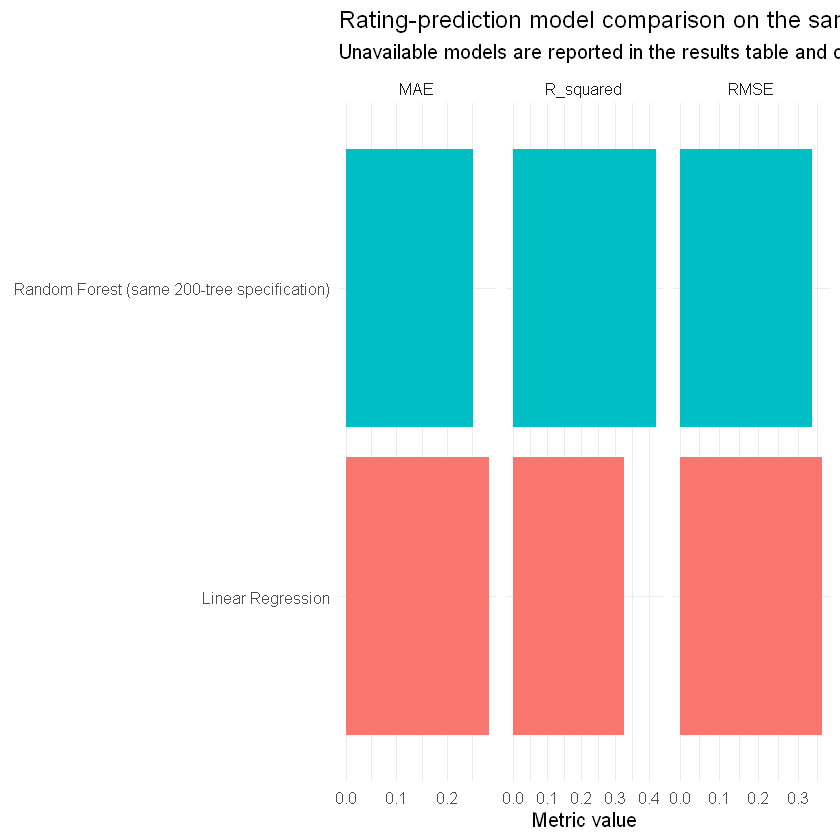

In [144]:
# NOVELTY FEATURE 2: Comparative Rating Prediction Models
novelty2_plot_data <- novelty2_results %>%
  filter(status == "Available") %>%
  select(model, MAE, RMSE, R_squared) %>%
  tidyr::pivot_longer(
    cols = c(MAE, RMSE, R_squared), names_to = "metric", values_to = "value"
  )

ggplot(novelty2_plot_data, aes(x = reorder(model, value), y = value, fill = model)) +
  geom_col(show.legend = FALSE) +
  coord_flip() +
  facet_wrap(~metric, scales = "free_x") +
  labs(
    title = "Rating-prediction model comparison on the same held-out test set",
    subtitle = "Unavailable models are reported in the results table and omitted here",
    x = NULL, y = "Metric value"
  ) +
  theme_minimal(base_size = 12)


## NOVELTY FEATURE 3: SHAP-Based Explainable Machine Learning

This section explains the notebook's existing `rf_model` (not the separate comparison fit). `fastshap` is not installed and is unavailable from the configured CRAN repository in this R environment. Since this Random Forest has only five predictors, the code uses a compatible, package-free, model-agnostic **exact Shapley calculation over all feature coalitions**, averaging predictions over a reproducible sample of training rows. It preserves factor columns and training levels for every prediction. The calculation is exact for the finite background sample; the sample approximates the full training distribution.

The global chart ranks mean absolute SHAP contributions, the dependence chart shows how the `votes` contribution varies across held-out restaurants, and an individual chart decomposes one prediction relative to the background baseline. A positive SHAP value pushes the model prediction above that baseline; a negative value pushes it below. These describe model behavior, not causal effects.

In [145]:
# NOVELTY FEATURE 3: SHAP-Based Explainable Machine Learning
novelty3_fastshap_available <- requireNamespace("fastshap", quietly = TRUE)
if (!novelty3_fastshap_available) {
  message("fastshap is unavailable; using exact model-agnostic SHAP over all coalitions for the five-feature Random Forest.")
} else {
  message("fastshap is installed; the exact coalition calculation below is used for reproducible local-accuracy verification.")
}


fastshap is unavailable; using exact model-agnostic SHAP over all coalitions for the five-feature Random Forest.



Exact empirical SHAP local-additivity max error: 0 
      feature mean_absolute_shap
        votes         0.12030884
   book_table         0.06171069
    rest_type         0.03763470
 online_order         0.01600801
     location         0.01141491


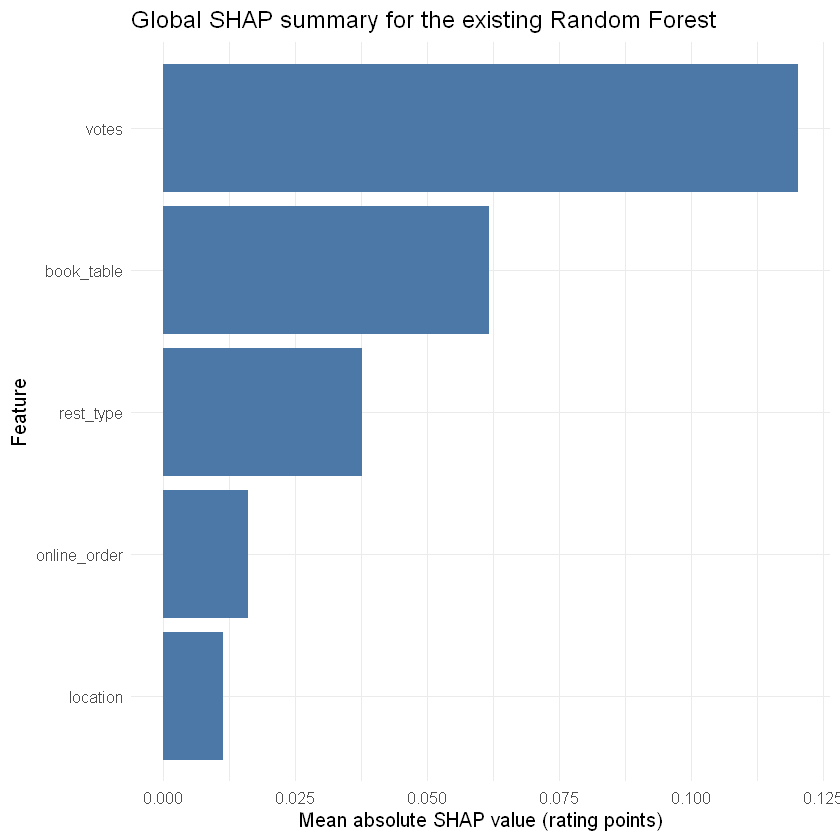

Individual held-out prediction: 3.634  | background baseline: 3.7111  | baseline plus SHAP sum: 3.634 
      feature  shap_value
        votes -0.09443872
    rest_type  0.04391676
     location  0.03897039
   book_table -0.03341959
 online_order -0.03210282


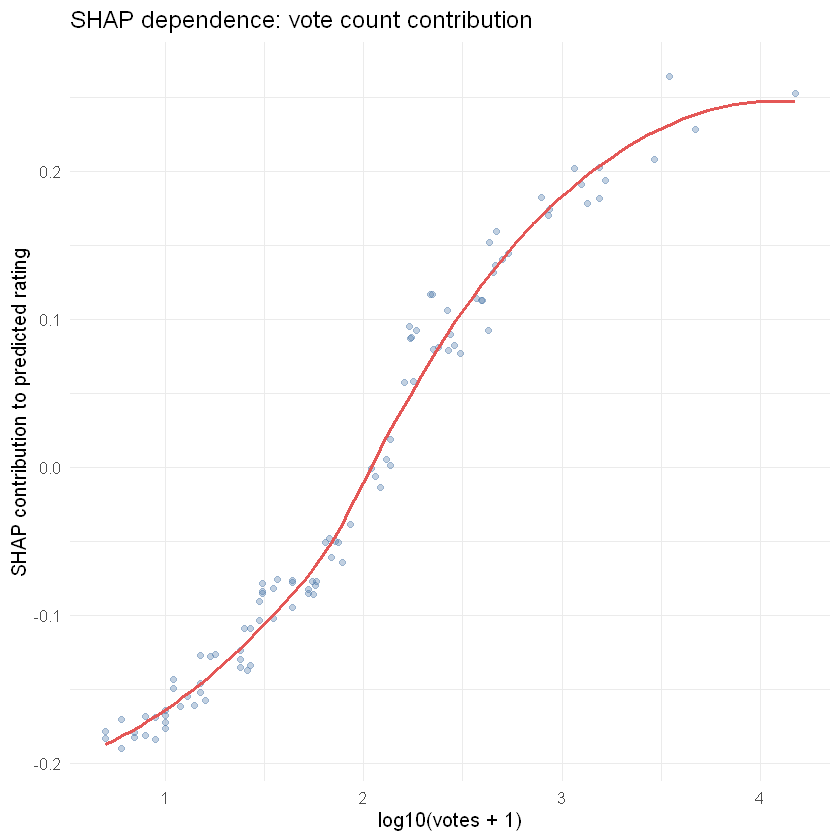

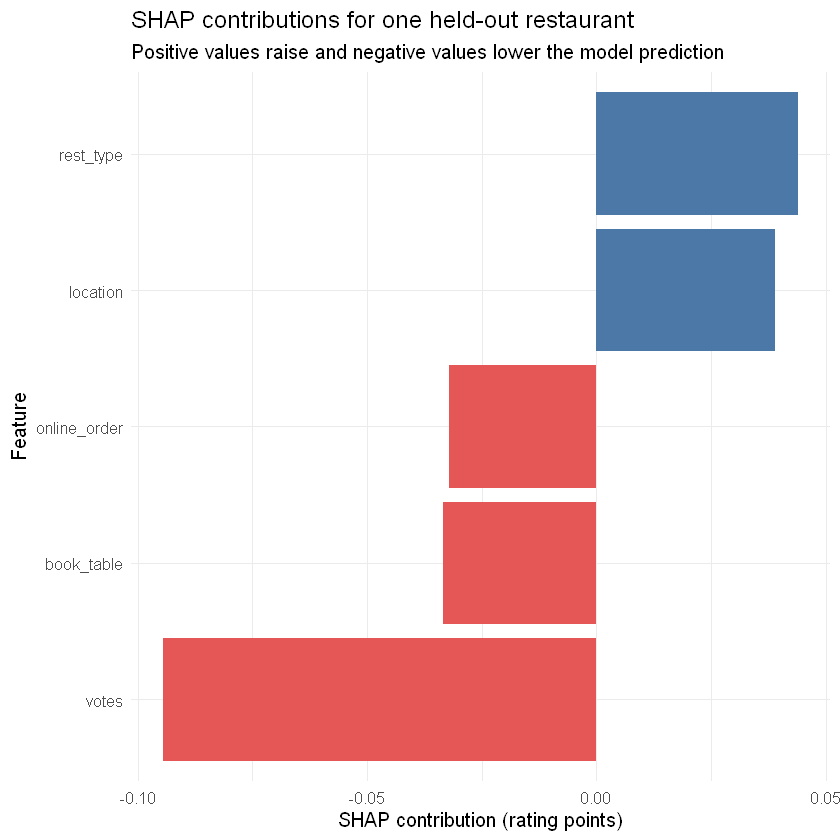

In [146]:
# NOVELTY FEATURE 3: SHAP-Based Explainable Machine Learning
novelty3_predictors <- setdiff(names(train), "rate")
novelty3_feature_count <- length(novelty3_predictors)
if (novelty3_feature_count > 10) {
  stop("Exact coalition SHAP is limited to 10 features; this model currently has ", novelty3_feature_count, ".")
}
novelty3_background_size <- min(100L, nrow(train))
novelty3_explain_size <- min(100L, nrow(test))
set.seed(2026)
novelty3_background_rows <- sample(seq_len(nrow(train)), novelty3_background_size)
novelty3_explain_rows <- sample(seq_len(nrow(test)), novelty3_explain_size)
novelty3_background <- train[novelty3_background_rows, novelty3_predictors, drop = FALSE]
novelty3_explain_data <- test[novelty3_explain_rows, novelty3_predictors, drop = FALSE]
novelty3_coalition_count <- bitwShiftL(1L, novelty3_feature_count)
novelty3_coalition_values <- vector("list", novelty3_coalition_count)
novelty3_background_rows_repeated <- rep(seq_len(nrow(novelty3_background)), times = nrow(novelty3_explain_data))
novelty3_explain_rows_repeated <- rep(seq_len(nrow(novelty3_explain_data)), each = nrow(novelty3_background))

for (novelty3_mask in 0:(novelty3_coalition_count - 1L)) {
  novelty3_synthetic_data <- novelty3_background[
    novelty3_background_rows_repeated, , drop = FALSE
  ]
  for (novelty3_feature_index in seq_len(novelty3_feature_count)) {
    novelty3_feature_bit <- bitwShiftL(1L, novelty3_feature_index - 1L)
    if (bitwAnd(novelty3_mask, novelty3_feature_bit) != 0L) {
      novelty3_feature <- novelty3_predictors[[novelty3_feature_index]]
      novelty3_synthetic_data[[novelty3_feature]] <-
        novelty3_explain_data[[novelty3_feature]][novelty3_explain_rows_repeated]
    }
  }
  novelty3_coalition_predictions <- as.numeric(stats::predict(
    rf_model, newdata = novelty3_synthetic_data
  ))
  novelty3_coalition_values[[novelty3_mask + 1L]] <- rowMeans(matrix(
    novelty3_coalition_predictions,
    nrow = nrow(novelty3_explain_data), byrow = TRUE
  ))
}

novelty3_shap_matrix <- matrix(
  0, nrow = nrow(novelty3_explain_data), ncol = novelty3_feature_count,
  dimnames = list(NULL, novelty3_predictors)
)
for (novelty3_feature_index in seq_len(novelty3_feature_count)) {
  novelty3_feature_bit <- bitwShiftL(1L, novelty3_feature_index - 1L)
  for (novelty3_mask in 0:(novelty3_coalition_count - 1L)) {
    if (bitwAnd(novelty3_mask, novelty3_feature_bit) == 0L) {
      novelty3_subset_size <- sum(as.integer(intToBits(novelty3_mask))[seq_len(novelty3_feature_count)])
      novelty3_weight <- factorial(novelty3_subset_size) *
        factorial(novelty3_feature_count - novelty3_subset_size - 1L) /
        factorial(novelty3_feature_count)
      novelty3_shap_matrix[, novelty3_feature_index] <-
        novelty3_shap_matrix[, novelty3_feature_index] + novelty3_weight * (
          novelty3_coalition_values[[novelty3_mask + novelty3_feature_bit + 1L]] -
            novelty3_coalition_values[[novelty3_mask + 1L]]
        )
    }
  }
}

novelty3_baseline_by_row <- novelty3_coalition_values[[1L]]
novelty3_individual_predictions <- as.numeric(stats::predict(
  rf_model, newdata = novelty3_explain_data
))
novelty3_reconstructed_predictions <- novelty3_baseline_by_row + rowSums(novelty3_shap_matrix)
novelty3_max_additivity_error <- max(abs(
  novelty3_individual_predictions - novelty3_reconstructed_predictions
))
if (!is.finite(novelty3_max_additivity_error) || novelty3_max_additivity_error > 1e-6) {
  stop("SHAP local additivity check failed; maximum error = ", novelty3_max_additivity_error)
}
cat("Exact empirical SHAP local-additivity max error:", novelty3_max_additivity_error, "\n")

novelty3_global_summary <- data.frame(
  feature = novelty3_predictors,
  mean_absolute_shap = colMeans(abs(novelty3_shap_matrix)),
  row.names = NULL
) %>% arrange(desc(mean_absolute_shap))
print(novelty3_global_summary, row.names = FALSE)
print(ggplot(novelty3_global_summary,
             aes(x = reorder(feature, mean_absolute_shap), y = mean_absolute_shap)) +
  geom_col(fill = "#4C78A8") + coord_flip() +
  labs(title = "Global SHAP summary for the existing Random Forest",
       x = "Feature", y = "Mean absolute SHAP value (rating points)") +
  theme_minimal(base_size = 12))

novelty3_votes_dependence <- data.frame(
  votes = novelty3_explain_data$votes,
  shap_value = novelty3_shap_matrix[, "votes"]
)
print(ggplot(novelty3_votes_dependence, aes(x = log10(votes + 1), y = shap_value)) +
  geom_point(alpha = 0.35, color = "#4C78A8") +
  geom_smooth(method = "loess", formula = y ~ x, se = FALSE, color = "#E45756") +
  labs(title = "SHAP dependence: vote count contribution",
       x = "log10(votes + 1)", y = "SHAP contribution to predicted rating") +
  theme_minimal(base_size = 12))

novelty3_individual_row <- 1L
novelty3_individual_contributions <- data.frame(
  feature = novelty3_predictors,
  shap_value = novelty3_shap_matrix[novelty3_individual_row, ],
  row.names = NULL
) %>% arrange(desc(abs(shap_value)))
cat("Individual held-out prediction:",
    round(novelty3_individual_predictions[novelty3_individual_row], 4),
    " | background baseline:", round(novelty3_baseline_by_row[novelty3_individual_row], 4),
    " | baseline plus SHAP sum:",
    round(novelty3_reconstructed_predictions[novelty3_individual_row], 4), "\n")
print(novelty3_individual_contributions, row.names = FALSE)
print(ggplot(novelty3_individual_contributions,
             aes(x = reorder(feature, shap_value), y = shap_value, fill = shap_value > 0)) +
  geom_col(show.legend = FALSE) + coord_flip() +
  scale_fill_manual(values = c("#E45756", "#4C78A8")) +
  labs(title = "SHAP contributions for one held-out restaurant",
       subtitle = "Positive values raise and negative values lower the model prediction",
       x = "Feature", y = "SHAP contribution (rating points)") +
  theme_minimal(base_size = 12))
